# **Preperations**

In [1]:
# --- Standard Libraries ---
import os
import json
import gc
from pathlib import Path
import time
import itertools

# --- Numerical and Data Analysis ---
import numpy as np
import pandas as pd
from scipy.interpolate import interp1d
from tqdm import tqdm

# --- Optimization and Statistics ---
import cvxpy as cp
import statsmodels.api as sm
from statsmodels.nonparametric.smoothers_lowess import lowess
from scipy.stats import poisson

# --- Image Processing and Medical Imaging ---
from skimage.data import shepp_logan_phantom
from skimage.transform import radon, iradon, rescale

# --- Visualization ---
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as ssim

# **Simulation Code**

In [2]:
# ============================================================
# PET Reconstruction Utilities: Probability Matrix Generation
# ============================================================

# Compute nth roots of unity representing detector positions
def nthRootsOfUnity(n):
    """
    Find the nth complex roots of unity.

    These roots represent detector positions evenly spaced around a circle.

    Parameters:
        n (int): Number of detectors.

    Returns:
        ndarray: Complex positions of detectors.
    """
    return np.exp(2j * np.pi / n * np.arange(n))

# Calculate the intersection length between two segments
def get_intersection(x,y):
    """
    Returns the intersection length of two given segments on the real axis.

    Parameters:
        x (tuple): Endpoints of the first segment.
        y (tuple): Endpoints of the second segment.

    Returns:
        float: Length of intersection (non-negative).
    """
    val = min(x[1],y[1])-max(x[0],y[0])
    if val<0:
        val = 0
    return val

# Build the probability matrix row for a given pixel position
from scipy.sparse import csr_matrix, lil_matrix

def build_prob_matrix_sparse(B_SQRT, D):

    B = B_SQRT**2
    D2 = D * D
    P_sparse = lil_matrix((B, D2), dtype=np.float32)

    grid_1d = np.linspace(-1+1./B_SQRT, 1-1./B_SQRT, num=B_SQRT) * np.sqrt(2)/2
    grid_2d = np.meshgrid(grid_1d, grid_1d)
    b_lst = (grid_2d[0] + grid_2d[1]*1j).flatten()
    roots = nthRootsOfUnity(D)

    print(f"Building Sparse Matrix for B={B}...")
    for b_ind, b in enumerate(tqdm(b_lst)):
        row_mat = build_matrix_row(b, roots)
        P_sparse[b_ind, :] = row_mat.flatten()

    return P_sparse.tocsr()
def build_matrix_row(b,roots):
    """
    Construct the probabilities matrix for each pixel 'b', relative to detector pairs.

    Parameters:
        b (complex): Pixel position in the complex plane.
        roots (ndarray): Detector positions as complex numbers.

    Returns:
        ndarray: A (D x D) symmetric matrix of intersection probabilities.
    """
    roots_updated = roots-b

    angles=np.angle(roots-b)
    normalized_angles=(((angles-angles[0])/(2*np.pi))%1)
    normalized_angles_w_ind = list(enumerate(normalized_angles))

    detectors = normalized_angles_w_ind
    for i in range(len(detectors)):
        if i == len(detectors)-1:
            next_angle = 1
        else:
            next_angle = detectors[i+1][1]
        detectors[i]=(detectors[i][0],detectors[i][1],next_angle)
    lower = [x for x in detectors if x[1]<0.5]
    upper = [x for x in detectors if x[2]>=0.5]
    lower_shifted = [(x[0],x[1]+0.5,x[2]+0.5) for x in lower]

    D=len(roots)
    prob_lst = []
    prob_mat = np.zeros((D,D))

    iter_upper = iter(upper)
    iter_lower = iter(lower_shifted)
    detector_upper = next(iter_upper)
    detector_lower = next(iter_lower)

    while True:
        val = get_intersection((detector_upper[1],detector_upper[2]),
                         (detector_lower[1],detector_lower[2]))
        if val>1e-4:
            prob_lst.append((detector_upper[0],detector_lower[0],(2*val)))
            prob_mat[detector_upper[0],detector_lower[0]]=2*val

        try:
            if detector_upper[2]<detector_lower[2]:
                detector_upper = next(iter_upper)
            else:
                detector_lower = next(iter_lower)
        except StopIteration:
            #print("done")
            break
    prob_mat = prob_mat + prob_mat.transpose()
    #normalize the total probability is 2
    prob_mat = 2 * prob_mat / np.sum(prob_mat)
    if prob_mat.diagonal().sum():
        print("non zero diag",prob_mat.diagonal(),b)
    return prob_mat

# Generate full probability tensor for all pixels in the imaging grid
def build_prob_matrix(B_SQRT,D):
    """
    Constructs the entire probability tensor for the imaging system.

    Parameters:
        B_SQRT (int): Square root of the total number of pixels in the image grid.
        D (int): Number of detectors.

    Returns:
        ndarray: Probability tensor with shape (B_SQRT^2, D, D).
    """
    grid_1d=np.linspace(-1+1./B_SQRT,1-1./B_SQRT,num=B_SQRT)*np.sqrt(2)/2
    grid_2d=np.meshgrid(grid_1d,grid_1d)
    b_lst=(grid_2d[0]+grid_2d[1]*1j).flatten()
    roots = nthRootsOfUnity(D)
    P = np.zeros((B_SQRT*B_SQRT,D,D), dtype=np.float32)
    for b_ind,b in enumerate(b_lst):
        P[b_ind] = build_matrix_row(b,roots)
    return P

# Mean Squared Error calculation utility
def mse(a,b):
    """
    Calculate Mean Squared Error between two arrays.

    Parameters:
        a, b (array-like): Arrays of true and estimated values.

    Returns:
        float: Mean squared error.
    """
    return np.square(np.array(a)-np.array(b)).mean()




# **PET Class**

In [3]:
# ===============================================
# PET Simulation and Reconstruction Class
# ===============================================


class PET:
    def __init__(self, B_SQRT=20, D=400, beta=0.8, tau=1e-7, T=1, f_factor=1e6, seed=2, external_image=None):
        # --- Hyperparameters and Dimensions ---
        self.B_SQRT = B_SQRT
        self.B = B_SQRT**2 # Total number of pixels
        self.D = D         # Number of detector elements
        self.T = T         # Scan duration (seconds)
        self.beta = beta   # Attenuation factor
        self.tau = tau     # Timing window (Randoms generation)
        self.f_factor = f_factor # Signal intensity scaling

        # --- Indexing Structures ---
        self.i_upper_diag = np.triu_indices(D)
        self.i_lower = np.tril_indices(D, -1)
        self.i_diag = np.diag_indices(D)

        np.random.seed(seed)

        # --- Construct probability system matrix P ---
        self.build_prob_matrix()

        # --- Build the ground truth digital phantom ---
        self.build_true_image(external_image=external_image)

        # --- Create flattened P_xmat for simulation and OSEM/BSREM ---
        # Normalized by attenuation (1-beta)^2 for detector pair sensitivity
        print("Initializing P_xmat...")
        self.P_xmat = self.P.reshape(self.B, -1).T.astype(np.float32) * (1 - self.beta)**2

        # --- Construct high-speed lookup structures for Gibbs sampling ---
        self.build_gibbs_structures()

        # --- Memory Management: Retain marginal sums and clear dense matrix P ---
        self.P_singles = self.P.sum(axis=2)
        print("Cleaning up memory...")
        del self.P
        gc.collect()

        print(f"PET Object initialized. Ready for simulation and reconstruction.")

    def build_prob_matrix(self):
        """ Computes the system matrix using external geometric modeling. """
        self.P = build_prob_matrix(self.B_SQRT, self.D).astype(np.float32)

    def build_true_image(self, external_image=None):
        """
        Generates the ground-truth digital phantom.
        If external_image is provided, it resizes and normalizes it.
        Otherwise, it generates a standard Shepp-Logan phantom.
        """
        if external_image is not None:
            # Rescale external image to match system resolution
            from skimage.transform import resize
            image_rescaled = resize(external_image, (self.B_SQRT, self.B_SQRT), anti_aliasing=True)
            self.f_true = image_rescaled.astype(float)
        else:
            # Default: Generate Shepp-Logan Phantom
            phantom = shepp_logan_phantom()
            self.f_true = rescale(phantom, self.B_SQRT / phantom.shape[0])

        # Normalize image by f_factor (Critical for Poisson noise statistics)
        self.f_true = self.f_factor * self.f_true / (self.f_true.sum() + 1e-10)
        self.f_true = self.f_true.flatten()
        print(f"True image built. Sum of intensity: {self.f_true.sum():.2f}")

    def build_P_lambda_mats_initial(self):
        """
        Initial version of matrix construction for simulation purposes.
        Reshapes the system matrix P into a flattened format (D^2 x B).
        """
        D, B = self.D, self.B
        # Flatten P to a (B, D^2) representation
        P_vals = self.P.reshape(B, -1)

        # Transpose to (D^2, B) and apply attenuation factor (1-beta)^2
        self.P_xmat = P_vals.T * (1 - self.beta)**2

    def build_gibbs_structures(self):
        """
        Builds memory-efficient data structures required for Gibbs sampling.
        Constructs a lookup list of non-zero Line-of-Response (LOR) indices
        and their corresponding probabilities for each pixel 'b'.
        """
        print("Building Gibbs structures...")
        D, B = self.D, self.B
        D2 = D * D

        # Work directly with the transposed flat matrix to optimize memory
        # P_flat_T is a (B x D^2) matrix
        P_flat_T = self.P_xmat.T

        self.P_b_lst = []
        for b in range(B):
            # Identify non-zero LORs contributing to pixel b
            row_b = P_flat_T[b]
            ind_ne_0 = np.nonzero(row_b)[0]

            self.P_b_lst.append({
                "ind": ind_ne_0,
                "probs": row_b[ind_ne_0] # Includes pre-calculated (1-beta)^2
            })
        print("Gibbs structures ready.")

    def run_simulation_with_randoms(self):
        """
        Simulates the PET data acquisition process.
        Generates forward projections comprising True Coincidences and
        additive Random Coincidences (if tau > 0).
        """
        print(f"Running Simulation (tau={self.tau})...")

       # 1. Compute expected True Coincidence rates (unattenuated)
        expected_true_flat = self.P_xmat.dot(self.f_true) * self.T

        # 2. Compute Random Coincidence rates based on single event rates
        if self.tau > 0:
            # Calculate singles for each detector: beta * (1-beta) * P_singles^T * f_true
            s_vec = self.beta * (1 - self.beta) * (self.P_singles.T @ self.f_true)
            # Construct Randoms matrix: R_ij = 2 * tau * s_i * s_j
            r_mat = 2 * self.tau * np.outer(s_vec, s_vec)
            r_mat[self.i_diag] *= 0.5 # Apply diagonal correction for self-coincidences
            self.r_flat = r_mat.flatten()
        else:
            self.r_flat = np.zeros(self.D**2)

        # 3. Sum expected rates (True + Randoms) to get the total expectation (lambda_bar)
        self.expected_flat = expected_true_flat + (self.r_flat * self.T)

        # 4. Generate measured counts via Poisson stochastic sampling
        n_star_flat = np.random.poisson(self.expected_flat)
        self.n_star = n_star_flat.reshape(self.D, self.D)
        self.n_star[self.i_lower] = self.n_star.T[self.i_lower]
        self.n_star_flat = self.n_star.flatten()

        print(f"Simulation Done. Randoms fraction: {np.sum(self.r_flat*self.T)/np.sum(self.expected_flat):.2%}")


    def prepare_oracle_prior(self, n_prior_points=500):
        """
        Oracle Prior Construction: Builds a nonparametric prior from the ground truth (f_true)
        using the empirical distribution as per the Oracle shrinkage theory.
        """
        # Transform to log-space with a small offset for stability
        logf_plus_05 = np.log(self.f_true + 0.5)
        logf_mid = np.linspace(logf_plus_05.min(), logf_plus_05.max(), n_prior_points)

        # Compute the Empirical Cumulative Distribution Function (ECDF)
        logf_ecdf = np.array([np.sum(logf_plus_05 < (m + (logf_mid[1]-logf_mid[0])/2)) for m in logf_mid]) / self.B

        # Smooth the ECDF using LOWESS (Locally Weighted Scatterplot Smoothing)
        smoothed = lowess(logf_ecdf, logf_mid, frac=0.03, return_sorted=False)

        # Generate probability mass function (PMF) from the smoothed ECDF
        self.app_f_prob = np.diff(np.maximum.accumulate(smoothed), prepend=smoothed[0])
        self.app_f_prob = np.maximum(self.app_f_prob, 1e-12) # Floor probability to avoid zeros
        self.app_f_vals = np.exp(logf_mid) - 0.5
        print("Oracle Prior prepared successfully.")

    def run_oracle_gibbs(self, G, burn_in, f_start, n_prior_points=500, window_size=51):
        """
        Oracle Gibbs Sampler: A full Python implementation of the iterative Bayesian
        reconstruction method originally developed in R.
        """
        if not hasattr(self, 'app_f_vals'):
            self.prepare_oracle_prior()
        scale = self.T
        half_win = window_size // 2

        # Initialize sampling array (G samples for each of B pixels)
        f_gbbs = np.zeros((self.B, G))

        # Starting point: Typically initialized with OSEM or ground truth
        f_gbbs[:, 0] = f_start

        # Initialize the expected projection (lambda) for all detector pairs
        lambda_ij_tmp = (self.P_xmat @ f_gbbs[:, 0]) * scale + (self.r_flat * scale)
        n_star_flat = self.n_star.flatten()
        self.oracle_mse_hist = []
        self.oracle_ll_hist = []

        for g in range(1, G):
            # Randomize pixel update order for better mixing
            order_B = np.random.permutation(self.B)
            f_gbbs[:, g] = f_gbbs[:, g-1] # Copy values from previous step

            # Iterate over each pixel in random order
            for b_tmp in tqdm(order_B, desc=f"Gibbs Sample {g}/{G}", leave=False):

                # 1. Locate the nearest intensity values in the prior (Local window)
                app_f_ind = np.searchsorted(self.app_f_vals, f_gbbs[b_tmp, g])
                ind_min = max(0, min(len(self.app_f_vals) - window_size, app_f_ind - half_win))
                ind_max = ind_min + window_size
                app_f_tmp = self.app_f_vals[ind_min:ind_max]

                # 2. Retrieve relevant LOR indices for current pixel 'b'
                lor_indices = self.P_b_lst[b_tmp]['ind']
                if len(lor_indices) == 0: continue

                # 3. Calculate Likelihood for all candidates in the window (Vectorized)
                diff_f = app_f_tmp - f_gbbs[b_tmp, g]
                delta_lambda = np.outer(self.P_b_lst[b_tmp]['probs'], diff_f) * scale
                new_lambdas = lambda_ij_tmp[lor_indices][:, np.newaxis] + delta_lambda + 1e-5

                # Compute Log-Poisson Likelihood: k*log(lam) - lam
                loglik_mat = n_star_flat[lor_indices][:, np.newaxis] * np.log(new_lambdas) - new_lambdas
                row_sum = loglik_mat.sum(axis=0)

                # 4. Sample from the Posterior distribution (Likelihood * Prior)
                prob_vec = np.exp(row_sum - np.max(row_sum)) * self.app_f_prob[ind_min:ind_max]
                prob_vec /= prob_vec.sum()

                # Select new intensity value based on posterior probabilities
                ind_smp = np.random.choice(len(app_f_tmp), p=prob_vec)

                # 5. Update pixel value and the corresponding expected projections
                lambda_ij_tmp[lor_indices] = new_lambdas[:, ind_smp]
                f_gbbs[b_tmp, g] = app_f_tmp[ind_smp]
            # Track convergence metrics
            current_f = f_gbbs[:, g]
            self.oracle_mse_hist.append(np.mean((current_f - self.f_true)**2))
            self.oracle_ll_hist.append(self.calculate_ll(current_f))

        # Compute Posterior Mean after the burn-in period
        self.f_pst_mn = np.mean(f_gbbs[:, burn_in:], axis=1)
        return self.f_pst_mn


    def plot_full_oracle_comparison(self, f_oracle_mn, f_em):
        """
        Extended visualization and metric evaluation suite for PET reconstruction:
        1. Visual reconstruction comparison (True vs. EM vs. Oracle).
        2. Pixel value histograms (log scale).
        3. Empirical Cumulative Distribution Function (eCDF) comparison.
        4. Goodness of Fit scatter plots (expected lambda vs. observed n_star).
        5. 1D Profile Slice (cross-section).
        6. Log-Likelihood (ll) convergence tracking.

        Args:
            f_oracle_mn (numpy.ndarray): Reconstructed image array using Oracle Gibbs.
            f_em (numpy.ndarray): Reconstructed image array using OSEM/EM.
        """

        # Internal helper to calculate quality metrics (MSE and SNR)
        def get_metrics(f_hat):
            mse_val = np.mean((f_hat - self.f_true)**2)
            snr_val = 10 * np.log10(np.sum(self.f_true**2) / np.sum((f_hat - self.f_true)**2))
            return mse_val, snr_val

        mse_em, snr_em = get_metrics(f_em)
        mse_ora, snr_ora = get_metrics(f_oracle_mn)

        # Setup base variables for plotting
        images = [self.f_true, f_em, f_oracle_mn]
        titles = ["True f", f"EM Recon\nSNR: {snr_em:.2f}dB", f"Oracle Gibbs\nSNR: {snr_ora:.2f}dB"]
        colors = ["black", "red", "green"]

        # --- Plot 1: Visual Reconstruction Comparison ---
        fig, axes = plt.subplots(1, 3, figsize=(18, 5))
        for ax, img, title in zip(axes, images, titles):
            im = ax.imshow(img.reshape(self.B_SQRT, self.B_SQRT), cmap='hot')
            ax.set_title(title)
            plt.colorbar(im, ax=ax)
            ax.axis('off')
        plt.show()

        # --- Plot 2: Pixel Value Histograms (Log Scale) ---
        fig, axes = plt.subplots(1, 3, figsize=(18, 5))
        for i, (ax, img, title) in enumerate(zip(axes, images, titles)):
            ax.hist(img, bins=50, color=colors[i], alpha=0.7)
            ax.set_yscale('log')
            ax.set_title(f"Histogram: {title.splitlines()[0]}")
            ax.set_xlabel("Pixel Value")
            ax.set_ylabel("Frequency (log scale)")
            ax.grid(True, alpha=0.2)
        plt.tight_layout()
        plt.show()

        # --- Plot 3: eCDF Comparison and 1D Profile Slice ---
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

        # A. Empirical Cumulative Distribution Function (eCDF)
        for img, label, color in zip(images, ["True", "EM", "Oracle"], colors):
            sorted_vals = np.sort(img)
            yvals = np.arange(len(sorted_vals)) / float(len(sorted_vals))
            ax1.step(sorted_vals, yvals, label=label, color=color)
        ax1.set_title("eCDF Comparison: True vs EM vs Oracle")
        ax1.set_xlabel("f values")
        ax1.set_ylabel("Cumulative Probability")
        ax1.legend()
        ax1.grid(True, alpha=0.3)

        # B. 1D Profile Slice (Center Row)
        mid_row = self.B_SQRT // 2
        true_slice = self.f_true.reshape(self.B_SQRT, self.B_SQRT)[mid_row, :]
        em_slice = f_em.reshape(self.B_SQRT, self.B_SQRT)[mid_row, :]
        ora_slice = f_oracle_mn.reshape(self.B_SQRT, self.B_SQRT)[mid_row, :]

        ax2.plot(true_slice, color='black', label='True', linewidth=2)
        ax2.plot(em_slice, color='red', linestyle='--', label='EM', alpha=0.8)
        ax2.plot(ora_slice, color='green', label='Oracle', alpha=0.8)
        ax2.set_title(f"1D Profile Scan (Row {mid_row})")
        ax2.set_xlabel("Pixel Index")
        ax2.set_ylabel("Intensity")
        ax2.legend()
        ax2.grid(True, alpha=0.3)
        plt.show()

        # --- Plot 4: Goodness of Fit & OSEM ll Convergence ---
        fig, axes = plt.subplots(1, 4, figsize=(22, 5)) # Configured for 4 columns
        n_star_flat = self.n_star.flatten()

        lambda_em = self.P_xmat @ f_em
        lambda_true = self.P_xmat @ self.f_true
        lambda_ora = self.P_xmat @ f_oracle_mn
        lams = [lambda_true, lambda_em, lambda_ora]
        titles_gof = ["True Fit", "EM Fit", "Oracle Fit"]

        # First 3 columns: Goodness of Fit scatter plots
        for i in range(3):
            llik = np.sum(poisson.logpmf(n_star_flat, lams[i] + 1e-5))
            axes[i].scatter(lams[i], n_star_flat, alpha=0.3, s=10)
            axes[i].plot([0, n_star_flat.max()], [0, n_star_flat.max()], 'r--')
            axes[i].set_title(f"{titles_gof[i]}\nLog-Lik: {llik:.2f}")
            axes[i].set_xlabel("Expected (lambda)")
            axes[i].set_ylabel("Observed (n_star)")

        # Fourth column: OSEM ll Convergence tracking
        if hasattr(self, 'osem_objs') and len(self.osem_objs) > 0:
            axes[3].plot(self.osem_objs, color='blue', linewidth=1.5)
            axes[3].set_title("OSEM Convergence\n Log-Likelihood")
            axes[3].set_xlabel("Sub-iteration")
            axes[3].set_ylabel("ll Value")
            axes[3].grid(True, alpha=0.3)
        else:
            axes[3].text(0.5, 0.5, 'No ll data available', ha='center', va='center')
            axes[3].set_title("OSEM Convergence")

        plt.tight_layout()
        plt.show()

        # Print numerical summary to console
        print("\n" + "="*30)
        print("SUMMARY STATISTICS")
        print("="*30)
        print(f"EM MSE:     {mse_em:.6f} | SNR: {snr_em:.2f} dB")
        print(f"Oracle MSE: {mse_ora:.6f} | SNR: {snr_ora:.2f} dB")
        print(f"Improvement: {snr_ora - snr_em:.2f} dB")
        print("="*30)

    def _get_metrics(self, f_hat):
        """
        Internal utility method to calculate comprehensive error metrics.

        Args:
            f_hat (numpy.ndarray): The reconstructed image array to evaluate.

        Returns:
            tuple: Contains (MSE, RMSE, SNR)
        """

        mse_val = np.mean((f_hat - self.f_true)**2)
        rmse_val = np.sqrt(mse_val)
        # Add epsilon to denominator to prevent potential division by zero
        snr_val = 10 * np.log10(np.sum(self.f_true**2) / (np.sum((f_hat - self.f_true)**2) + 1e-10))
        return mse_val, rmse_val, snr_val

    def print_summary_statistics(self, f_osem, f_bsrem, f_oracle):
        """
        Computes and prints a formatted console summary of the global error metrics
        (RMSE and SNR) for the provided reconstruction arrays. It also calculates
        the relative percentage improvement of the Oracle Gibbs sampler over the baselines.

        Args:
            f_osem (numpy.ndarray): Reconstructed image array using OSEM.
            f_bsrem (numpy.ndarray or None): Reconstructed image array using BSREM.
                                             Can be None if the BSREM baseline is skipped.
            f_oracle (numpy.ndarray): Reconstructed image array using Oracle Gibbs.

        # Retrieve global metrics for the mandatory baselines
        """

        _, rmse_osem, snr_osem = self._get_metrics(f_osem)
        _, rmse_ora, snr_ora = self._get_metrics(f_oracle)

        print("\n" + "="*50)
        print("SUMMARY STATISTICS")
        print("="*50)
        print(f"OSEM   -> RMSE: {rmse_osem:.6f} | SNR: {snr_osem:.2f} dB")

        # Dynamically include BSREM metrics only if the array was provided
        if f_bsrem is not None:
            _, rmse_bsrem, snr_bsrem = self._get_metrics(f_bsrem)
            print(f"BSREM  -> RMSE: {rmse_bsrem:.6f} | SNR: {snr_bsrem:.2f} dB")

        print(f"Oracle -> RMSE: {rmse_ora:.6f} | SNR: {snr_ora:.2f} dB")
        print("-" * 50)

        # Calculate relative RMSE percentage decrease (improvement) against OSEM
        imp_osem = ((rmse_osem - rmse_ora) / rmse_osem) * 100 if rmse_osem > 0 else 0
        print(f"Oracle RMSE Improvement over OSEM:  {imp_osem:.2f}%")

        # Calculate relative RMSE percentage decrease (improvement) against BSREM
        if f_bsrem is not None:
            imp_bsrem = ((rmse_bsrem - rmse_ora) / rmse_bsrem) * 100 if rmse_bsrem > 0 else 0
            print(f"Oracle RMSE Improvement over BSREM: {imp_bsrem:.2f}%")

        print("="*50)



    def plot_reconstructions(self, f_osem, f_bsrem, f_oracle, save_prefix=None):
        """
        Generates a side-by-side visual comparison of the reconstructed images
        against the ground truth phantom, including global error metrics in the titles.

        Args:
            f_osem (numpy.ndarray): Reconstructed image array using OSEM.
            f_bsrem (numpy.ndarray or None): Reconstructed image array using BSREM.
            f_oracle (numpy.ndarray): Reconstructed image array using Oracle Gibbs.
            save_prefix (str, optional): If provided, saves the figure to disk using
                                         this prefix. Defaults to None.


        # Calculate global quantitative metrics for the mandatory arrays
        """
        _, rmse_osem, snr_osem = self._get_metrics(f_osem)
        _, rmse_ora, snr_ora = self._get_metrics(f_oracle)

        # Initialize image and title lists with the Ground Truth and OSEM baseline
        images = [self.f_true, f_osem]
        titles = ["True Phantom", f"OSEM\nRMSE: {rmse_osem:.4f} | SNR: {snr_osem:.2f}dB"]

        # Dynamically append BSREM data if it was computed in the current scenario
        if f_bsrem is not None:
            _, rmse_bsrem, snr_bsrem = self._get_metrics(f_bsrem)
            images.append(f_bsrem)
            titles.append(f"BSREM\nRMSE: {rmse_bsrem:.4f} | SNR: {snr_bsrem:.2f}dB")

        # Append the proposed Oracle Gibbs method
        images.append(f_oracle)
        titles.append(f"Oracle Gibbs\nRMSE: {rmse_ora:.4f} | SNR: {snr_ora:.2f}dB")

        # Setup dynamic subplot grid based on the number of algorithms evaluated
        n_cols = len(images)
        fig, axes = plt.subplots(1, n_cols, figsize=(5.5 * n_cols, 5))

        for ax, img, title in zip(axes, images, titles):
            # Reshape 1D arrays back to 2D spatial dimensions for heatmap visualization
            im = ax.imshow(img.reshape(self.B_SQRT, self.B_SQRT), cmap='hot')
            ax.set_title(title, fontsize=12)
            plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
            ax.axis('off')

        plt.tight_layout()

        # Export the figure if a save path prefix was specified
        if save_prefix:
            plt.savefig(f"{save_prefix}_1_recons.png", bbox_inches='tight', dpi=150)
        plt.show()


    def plot_histograms(self, f_osem, f_bsrem, f_oracle, save_prefix=None):
        """
        Plots pixel intensity histograms on a logarithmic frequency scale to analyze
        the statistical distribution of intensities across the different algorithms.

        Args:
            f_osem (numpy.ndarray): Reconstructed image array using OSEM.
            f_bsrem (numpy.ndarray or None): Reconstructed image array using BSREM.
            f_oracle (numpy.ndarray): Reconstructed image array using Oracle Gibbs.
            save_prefix (str, optional): If provided, saves the figure to disk using
                                         this prefix. Defaults to None.
        """

        # Initialize lists for images, titles, and uniform color mapping
        images = [self.f_true, f_osem]
        titles = ["True f", "OSEM"]
        colors = ["black", "red"]

        # Dynamically append BSREM parameters if it exists in the pipeline
        if f_bsrem is not None:
            images.append(f_bsrem)
            titles.append("BSREM")
            colors.append("purple")

        # Append Oracle Gibbs parameters
        images.append(f_oracle)
        titles.append("Oracle Gibbs")
        colors.append("green")

        # Setup dynamic subplot grid
        n_cols = len(images)
        fig, axes = plt.subplots(1, n_cols, figsize=(5.5 * n_cols, 5))

        for i, (ax, img, title) in enumerate(zip(axes, images, titles)):
            # Plot the histogram using 50 bins
            ax.hist(img, bins=50, color=colors[i], alpha=0.7)
            # Apply logarithmic scale to effectively visualize low-frequency tails
            ax.set_yscale('log')
            ax.set_title(f"Histogram: {title}", fontsize=12)
            ax.set_xlabel("Pixel Value")
            ax.set_ylabel("Frequency (log scale)")
            ax.grid(True, alpha=0.2)

        plt.tight_layout()

        # Export the figure if a save path prefix was specified
        if save_prefix:
            plt.savefig(f"{save_prefix}_2_hist.png", bbox_inches='tight', dpi=150)
        plt.show()

    def plot_ecdf(self, f_osem, f_bsrem, f_oracle, save_prefix=None):
        """
        Computes and plots the Empirical Cumulative Distribution Function (eCDF)
        for the reconstructed images. This visualization assesses how well each
        algorithm preserves the underlying statistical distribution of pixel intensities.

        Args:
            f_osem (numpy.ndarray): Reconstructed image array using OSEM.
            f_bsrem (numpy.ndarray or None): Reconstructed image array using BSREM.
            f_oracle (numpy.ndarray): Reconstructed image array using Oracle Gibbs.
            save_prefix (str, optional): If provided, saves the figure to disk using
                                         this prefix. Defaults to None.
        """

        # Initialize base data lists for True Phantom and OSEM
        images = [self.f_true, f_osem]
        labels = ["True", "OSEM"]
        colors = ["black", "red"]

        # Dynamically append BSREM data if available
        if f_bsrem is not None:
            images.append(f_bsrem)
            labels.append("BSREM")
            colors.append("purple")

        # Append Oracle Gibbs data
        images.append(f_oracle)
        labels.append("Oracle")
        colors.append("green")

        plt.figure(figsize=(10, 6))

        # Calculate and plot the step function for each image array
        for img, label, color in zip(images, labels, colors):
            # Sort the pixel intensities in ascending order
            sorted_vals = np.sort(img)
            # Generate cumulative probabilities spanning [0, 1)
            yvals = np.arange(len(sorted_vals)) / float(len(sorted_vals))

            # Use a slightly thicker line for the Ground Truth reference
            line_width = 2 if label == "True" else 1.5
            plt.step(sorted_vals, yvals, label=label, color=color, linewidth=line_width)

        plt.title("eCDF Comparison", fontsize=14)
        plt.xlabel("Intensity values (f)")
        plt.ylabel("Cumulative Probability")
        plt.legend()
        plt.grid(True, alpha=0.3)

        # Export the figure if a save path prefix was specified
        if save_prefix:
            plt.savefig(f"{save_prefix}_3_ecdf.png", bbox_inches='tight', dpi=150)
        plt.show()

    def plot_line_profiles(self, f_osem, f_bsrem, f_oracle, rows_to_plot=None, save_prefix=None):
        """
        Extracts and visualizes 1D horizontal cross-sections (line profiles) of the
        2D reconstructed images. This allows for spatial evaluation of resolution,
        edge preservation, and noise variance across specific anatomical structures.

        Args:
            f_osem (numpy.ndarray): Reconstructed image array using OSEM.
            f_bsrem (numpy.ndarray or None): Reconstructed image array using BSREM.
            f_oracle (numpy.ndarray): Reconstructed image array using Oracle Gibbs.
            rows_to_plot (list of int, optional): Specific row indices to extract.
                                                  Defaults to the middle row and 65% depth.
            save_prefix (str, optional): If provided, saves the figure to disk using
                                         this prefix. Defaults to None.
        """

        # Default to capturing the center of the image and a slightly lower section (lesions)
        if rows_to_plot is None:
            rows_to_plot = [self.B_SQRT // 2, int(self.B_SQRT * 0.65)]

        # Reshape flat 1D arrays to 2D spatial matrices for row extraction
        img_true = self.f_true.reshape(self.B_SQRT, self.B_SQRT)
        img_osem = f_osem.reshape(self.B_SQRT, self.B_SQRT)
        img_ora = f_oracle.reshape(self.B_SQRT, self.B_SQRT)

        img_bsrem = None
        if f_bsrem is not None:
            img_bsrem = f_bsrem.reshape(self.B_SQRT, self.B_SQRT)

        # Setup dynamic subplot grid based on the number of rows requested
        fig, axes = plt.subplots(1, len(rows_to_plot), figsize=(8 * len(rows_to_plot), 5))

        # Ensure 'axes' is iterable even if only one row is plotted
        if len(rows_to_plot) == 1:
            axes = [axes]

        for ax, row_idx in zip(axes, rows_to_plot):
            # Plot Ground Truth as a solid black baseline
            ax.plot(img_true[row_idx, :], color='black', label='True', linewidth=2)

            # Plot OSEM with a dashed line to highlight noise variance
            ax.plot(img_osem[row_idx, :], color='red', linestyle='--', label='OSEM', alpha=0.7)

            # Plot BSREM (if available) with a dash-dot line
            if img_bsrem is not None:
                ax.plot(img_bsrem[row_idx, :], color='purple', linestyle='-.', label='BSREM', alpha=0.7)

            # Plot Oracle Gibbs as a solid green line over the baselines
            ax.plot(img_ora[row_idx, :], color='green', label='Oracle', alpha=0.9, linewidth=1.5)

            ax.set_title(f"1D Profile Scan (Row {row_idx})", fontsize=12)
            ax.set_xlabel("Pixel Index (X axis)")
            ax.set_ylabel("Intensity")
            ax.legend()
            ax.grid(True, alpha=0.3)

        plt.tight_layout()

        # Export the figure if a save path prefix was specified
        if save_prefix:
            plt.savefig(f"{save_prefix}_4_profiles.png", bbox_inches='tight', dpi=150)
        plt.show()

    def plot_shrinkage_analysis(self, f_osem, f_oracle, save_prefix=None):
        """
        Generates a statistical shrinkage plot comparing the initial unregularized
        estimates (OSEM) against the final regularized estimates (Oracle Gibbs).
        Includes Ground Truth reference to visualize shrinkage toward true modes.
        """
        fig, ax = plt.subplots(1, 1, figsize=(10, 8))

        max_val = np.max([np.max(f_osem), np.max(self.f_true)])


        ax.scatter(f_osem, self.f_true, alpha=1, color='orange', s=5, label='Ground Truth Ref')

        ax.scatter(f_osem, f_oracle, alpha=0.3, color='blue', s=15, label='Oracle vs OSEM')

        ax.plot([0, max_val], [0, max_val], 'k--', lw=1.5, alpha=0.6, label='Identity Line')


        #trend = lowess(f_oracle, f_osem, frac=0.1)
        #ax.plot(trend[:, 0], trend[:, 1], color='red', lw=2, label='Shrinkage Trend')

        ax.set_title("Statistical Shrinkage Analysis: Oracle vs OSEM", fontsize=14, fontweight='bold')
        ax.set_xlabel("OSEM Intensity (Initial/Noisy Estimate)", fontsize=12)
        ax.set_ylabel("Intensity (Oracle / Ground Truth)", fontsize=12)

        ax.grid(True, alpha=0.3)
        ax.legend()

        plt.tight_layout()
        if save_prefix:
            plt.savefig(f"{save_prefix}_shrinkage_with_truth.png", bbox_inches='tight', dpi=150)
        plt.show()

    # --- Convergence and Goodness of Fit Utilities ---

    def calculate_ll(self, f_hat):
        """
        Calculates the Log-Likelihood (LL) for a given image estimate
        under the Poisson observation model.

        Args:
            f_hat (numpy.ndarray): The estimated image intensity vector.

        Returns:
            float: The calculated Log-Likelihood value.
        """
        scale = self.T
        # Calculate expected photon counts (lambda) including system matrix, randoms, and scan time
        lambdas = (self.P_xmat @ f_hat) * scale + (self.r_flat * scale) + 1e-10
        return np.sum(self.n_star_flat * np.log(lambdas) - lambdas)

    def plot_gof_and_ll(self, f_osem, f_bsrem, f_oracle, save_prefix=None):
        """
        Visualizes the Goodness of Fit (GOF) for each reconstruction algorithm and
        plots the Log-Likelihood (ll) convergence history.

        The GOF scatter plots compare the expected Poisson rates (lambda) against
        the actually observed detector counts (n_star).

        Args:
            f_osem (numpy.ndarray): Reconstructed image array using OSEM.
            f_bsrem (numpy.ndarray or None): Reconstructed image array using BSREM.
            f_oracle (numpy.ndarray): Reconstructed image array using Oracle Gibbs.
            save_prefix (str, optional): If provided, saves the figure to disk. Defaults to None.
        """


        n_star_flat = self.n_star.flatten()
        scale = self.T

        # Calculate expected detector counts (lambdas) for Ground Truth and OSEM
        lambda_true = (self.P_xmat @ self.f_true) * scale + (self.r_flat * scale)
        lambda_osem = (self.P_xmat @ f_osem) * scale + (self.r_flat * scale)
        lambda_ora = (self.P_xmat @ f_oracle) * scale + (self.r_flat * scale)

        lams = [lambda_true, lambda_osem]
        titles = ["True Fit", "OSEM Fit"]

        # Dynamically append BSREM expectations if evaluated
        if f_bsrem is not None:
            lambda_bsrem = (self.P_xmat @ f_bsrem) * scale + (self.r_flat * scale)
            lams.append(lambda_bsrem)
            titles.append("BSREM Fit")

        lams.append(lambda_ora)
        titles.append("Oracle Fit")

        # Define grid layout: 1 column per algorithm's GOF + 1 extra for Convergence plot
        n_cols = len(lams) + 1
        fig, axes = plt.subplots(1, n_cols, figsize=(5.5 * n_cols, 5))

        # Generate Goodness of Fit scatter plots
        for i in range(len(lams)):
            ax = axes[i]
            # Calculate total log-likelihood for the title
            llik = np.sum(poisson.logpmf(n_star_flat, lams[i] + 1e-10))
            ax.scatter(lams[i], n_star_flat, alpha=0.3, s=10)

            max_plot_val = n_star_flat.max()
            # Reference line representing perfect fit (y = x)
            ax.plot([0, max_plot_val], [0, max_plot_val], 'r--')

            ax.set_title(f"{titles[i]}\nLog-Lik: {llik:.0f}", fontsize=11)
            ax.set_xlabel(r"Expected ($\lambda$)")
            ax.set_ylabel(r"Observed ($n^*$)")
            ax.grid(True, alpha=0.3)

        # Generate ll Convergence Plot in the final subplot
        ax = axes[-1]
        if hasattr(self, 'osem_objs') and len(self.osem_objs) > 0:
            ax.plot(self.osem_objs, color='red', linewidth=1.5, label='OSEM ll')
            ax.set_title("Algorithm Convergence\n Log-Likelihood", fontsize=11)
            ax.set_xlabel("Sub-iteration")
            ax.set_ylabel("ll Value")
            ax.legend()
            ax.grid(True, alpha=0.3)
        else:
            # Fallback if convergence tracking data is missing
            ax.text(0.5, 0.5, 'll data not available', ha='center', va='center')
            ax.set_title("Algorithm Convergence")

        plt.tight_layout()
        if save_prefix:
            plt.savefig(f"{save_prefix}_6_gof.png", bbox_inches='tight', dpi=150)
        plt.show()




    def plot_convergence_metrics(self, f_osem, f_bsrem, f_oracle, save_prefix=None):
        """
        Plots the convergence histories for both the Mean Squared Error (MSE)
        and the Log-Likelihood (ll).

        The visualization is split into a 3x2 grid:
        Left Column: Separate log-scale subplots for the MSE of each algorithm (shared Y-axis).
        Right Column: Separate plots for ll tracking sub-iteration updates and Gibbs samples,
                      each compared against the theoretical Ground Truth ll baseline.

        Args:
            f_osem (numpy.ndarray): Reconstructed image array using OSEM.
            f_bsrem (numpy.ndarray or None): Reconstructed image array using BSREM.
            f_oracle (numpy.ndarray): Reconstructed image array using Oracle Gibbs.
            save_prefix (str, optional): Prefix for saving the output figure. Defaults to None.
        """
        import matplotlib.pyplot as plt
        import numpy as np
        from matplotlib.ticker import MaxNLocator

        # Calculate the reference Log-Likelihood of the Ground Truth image
        true_ll = self.calculate_ll(self.f_true)

        # 1. Gather all active MSE data to calculate global shared Y-axis boundaries
        mse_all = []
        if hasattr(self, 'osem_mse_hist') and len(self.osem_mse_hist) > 0:
            mse_all.extend(self.osem_mse_hist)
        if f_bsrem is not None and hasattr(self, 'bsrem_mse_hist') and len(self.bsrem_mse_hist) > 0:
            mse_all.extend(self.bsrem_mse_hist)
        if hasattr(self, 'oracle_mse_hist') and len(self.oracle_mse_hist) > 0:
            mse_all.extend(self.oracle_mse_hist)

        # Set min/max bounds for the shared MSE scale
        if mse_all:
            min_mse, max_mse = min(mse_all), max(mse_all)
        else:
            min_mse, max_mse = 1, 100  # Fallback

        # 2. Setup the 3x2 Figure Grid
        fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(18, 16))
        fig.suptitle("Convergence Analysis: MSE and Log-Likelihood", fontsize=18, fontweight='bold', y=0.96)

        # ==========================================
        # Row 1: OSEM
        # ==========================================
        if hasattr(self, 'osem_mse_hist') and len(self.osem_mse_hist) > 0:
            ax = axes[0, 0]
            x_axis = np.arange(1, len(self.osem_mse_hist) + 1)
            ax.plot(x_axis, self.osem_mse_hist, color='red', linewidth=2)
            ax.set_title("OSEM MSE Convergence", fontsize=14, fontweight='bold')
            ax.set_ylabel("MSE (Log Scale)")
            ax.set_yscale('log')
            ax.set_ylim(min_mse, max_mse) # Applied shared scale
            ax.xaxis.set_major_locator(MaxNLocator(integer=True))
            ax.grid(True, which="both", alpha=0.3)

        if hasattr(self, 'osem_objs') and len(self.osem_objs) > 0:
            ax_ll = axes[0, 1]
            x_axis_ll = np.arange(1, len(self.osem_objs) + 1)
            ax_ll.plot(x_axis_ll, self.osem_objs, color='red', label='OSEM (Sub-iterations)', alpha=0.8, linewidth=2)
            ax_ll.axhline(y=true_ll, color='black', linestyle='--', linewidth=2, label='True f Likelihood')
            ax_ll.set_title("OSEM Log-Likelihood", fontsize=14, fontweight='bold')
            ax_ll.set_ylabel("ll Value")
            ax_ll.legend(loc='upper right')
            ax_ll.grid(True, alpha=0.3)

            # Dynamic zoom to avoid initial massive outlier spikes in OSEM
            recent_objs = self.osem_objs[-len(self.osem_objs)//2:] # Look at the second half of iterations
            y_min = min(np.min(recent_objs), true_ll)
            y_max = max(np.max(recent_objs), true_ll)
            ax_ll.set_ylim(y_min - abs(y_min)*0.05, y_max + abs(y_max)*0.05)

        # ==========================================
        # Row 2: BSREM
        # ==========================================
        if f_bsrem is not None and hasattr(self, 'bsrem_mse_hist') and len(self.bsrem_mse_hist) > 0:
            ax = axes[1, 0]
            x_axis = np.arange(1, len(self.bsrem_mse_hist) + 1)
            ax.plot(x_axis, self.bsrem_mse_hist, color='purple', linewidth=2)
            ax.set_title("BSREM MSE Convergence", fontsize=14, fontweight='bold')
            ax.set_ylabel("MSE (Log Scale)")
            ax.set_yscale('log')
            ax.set_ylim(min_mse, max_mse) # Applied shared scale
            ax.xaxis.set_major_locator(MaxNLocator(integer=True))
            ax.grid(True, which="both", alpha=0.3)

            if hasattr(self, 'bsrem_ll_hist') and len(self.bsrem_ll_hist) > 0:
                ax_ll = axes[1, 1]
                x_axis_ll = np.arange(1, len(self.bsrem_ll_hist) + 1)
                ax_ll.plot(x_axis_ll, self.bsrem_ll_hist, color='purple', label='BSREM', alpha=0.8, linewidth=2)
                ax_ll.axhline(y=true_ll, color='black', linestyle='--', linewidth=2, label='True f Likelihood')
                ax_ll.set_title("BSREM Log-Likelihood", fontsize=14, fontweight='bold')
                ax_ll.set_ylabel("ll Value")
                ax_ll.legend(loc='upper right')
                ax_ll.grid(True, alpha=0.3)

                # Dynamic zoom
                y_min = min(np.min(self.bsrem_ll_hist), true_ll)
                y_max = max(np.max(self.bsrem_ll_hist), true_ll)
                ax_ll.set_ylim(y_min - abs(y_min)*0.05, y_max + abs(y_max)*0.05)
        else:
            # Hide the axes if BSREM was not run
            axes[1, 0].set_visible(False)
            axes[1, 1].set_visible(False)

        # ==========================================
        # Row 3: Oracle Gibbs
        # ==========================================
        if hasattr(self, 'oracle_mse_hist') and len(self.oracle_mse_hist) > 0:
            ax = axes[2, 0]
            x_axis = np.arange(1, len(self.oracle_mse_hist) + 1)
            ax.plot(x_axis, self.oracle_mse_hist, color='green', linewidth=2)
            ax.set_title("Oracle Gibbs MSE Convergence", fontsize=14, fontweight='bold')
            ax.set_xlabel("Iteration / Sample Number")
            ax.set_ylabel("MSE (Log Scale)")
            ax.set_yscale('log')
            ax.set_ylim(min_mse, max_mse) # Applied shared scale
            ax.xaxis.set_major_locator(MaxNLocator(integer=True))
            ax.grid(True, which="both", alpha=0.3)

            if hasattr(self, 'oracle_ll_hist') and len(self.oracle_ll_hist) > 0:
                ax_ll = axes[2, 1]
                x_axis_ll = np.arange(1, len(self.oracle_ll_hist) + 1)
                ax_ll.plot(x_axis_ll, self.oracle_ll_hist, color='green', label='Oracle Gibbs', linewidth=2)
                ax_ll.axhline(y=true_ll, color='black', linestyle='--', linewidth=2, label='True f Likelihood')
                ax_ll.set_title("Oracle Gibbs Log-Likelihood", fontsize=14, fontweight='bold')
                ax_ll.set_xlabel("Iteration / Sample Number")
                ax_ll.set_ylabel("ll Value")
                ax_ll.legend(loc='upper right')
                ax_ll.grid(True, alpha=0.3)

                # Dynamic zoom
                y_min = min(np.min(self.oracle_ll_hist), true_ll)
                y_max = max(np.max(self.oracle_ll_hist), true_ll)
                ax_ll.set_ylim(y_min - abs(y_min)*0.05, y_max + abs(y_max)*0.05)

        # Final layout adjustments
        plt.tight_layout()
        plt.subplots_adjust(top=0.93)

        if save_prefix:
            plt.savefig(f"{save_prefix}_convergence_final.png", bbox_inches='tight', dpi=150)

        plt.show()



    def plot_full_comparison_suite(self, f_osem, f_bsrem, f_oracle, rows_to_plot=None, save_prefix=None):
        """
        Master execution function that sequentially triggers the entire suite
        of statistical, diagnostic, and visual evaluation methods.

        Args:
            f_osem (numpy.ndarray): Reconstructed image array using OSEM.
            f_bsrem (numpy.ndarray or None): Reconstructed image array using BSREM.
            f_oracle (numpy.ndarray): Reconstructed image array using Oracle Gibbs.
            rows_to_plot (list of int, optional): Specific row indices for 1D profiles.
            save_prefix (str, optional): Path prefix to save all generated figures.
        """
        print("\n--- Generating Master Evaluation Suite ---")
        if save_prefix:
            print(f"[*] Images will be saved to disk with prefix: {save_prefix}")

        self.print_summary_statistics(f_osem, f_bsrem, f_oracle)
        self.plot_reconstructions(f_osem, f_bsrem, f_oracle, save_prefix)
        self.plot_histograms(f_osem, f_bsrem, f_oracle, save_prefix)
        self.plot_ecdf(f_osem, f_bsrem, f_oracle, save_prefix)
        self.plot_line_profiles(f_osem, f_bsrem, f_oracle, rows_to_plot, save_prefix)
        self.plot_shrinkage_analysis(f_osem, f_oracle, save_prefix)
        # self.plot_gof_and_ll(f_osem, f_bsrem, f_oracle, save_prefix) # Currently disabled
        self.plot_convergence_metrics(f_osem, f_bsrem, f_oracle, save_prefix)
        print("\n--- Master Evaluation Suite Complete ---")

    import numpy as np
    import cvxpy as cp
    import time

    import numpy as np
    import cvxpy as cp
    import time

    def reconstruct_yigal_em(self, num_iter=30, solver_eps=1e-4, use_beta=None):
        """
        Global MLE (EM) with Randoms included.
        Uses the analytical solution for the M-step, avoiding CVXPY numerical instabilities.
        """
        print(f"Starting Yigal's EM (Global MLE with Randoms, Analytical M-Step), iterations={num_iter}")
        f_lst, llik_lst, mse_lst = [], [], []
        num_pixels = self.P_xmat.shape[1]
        n_star_flat = self.n_star.flatten()
        scale = getattr(self, 'T', 1.0)

        # 1. Initialization
        f_curr = np.ones(num_pixels) * (float(n_star_flat.sum()) / num_pixels)

        # 2. System Sensitivity
        ones_sinogram = np.ones(self.P_xmat.shape[0])
        sensitivity = (self.P_xmat.T.dot(ones_sinogram)) * scale
        sensitivity = np.maximum(sensitivity, 1e-12) # Prevent division by zero

        for i in range(num_iter):
            iter_start = time.time()

            # --- E-Step ---
            # Expected counts (including Randoms)
            expected_curr = (self.P_xmat.dot(f_curr) * scale) + (self.r_flat * scale) + 1e-10

            # Ratio of measured to expected
            d_curr = np.divide(n_star_flat, expected_curr, out=np.zeros_like(expected_curr), where=(expected_curr != 0))

            # Attributed counts backprojected to pixels
            attributed_counts = f_curr * (self.P_xmat.T.dot(d_curr) * scale)

            # --- M-Step (Analytical Maximum) ---
            # Replacing the unstable CVXPY block with the exact closed-form solution
            f_curr = attributed_counts / sensitivity
            f_curr = np.maximum(f_curr, 1e-12) # Enforce non-negativity constraint

            # --- Metrics tracking ---
            expected_for_ll = (self.P_xmat.dot(f_curr) * scale) + (self.r_flat * scale) + 1e-12
            llik = np.sum(n_star_flat * np.log(expected_for_ll) - expected_for_ll)

            mse_curr = 0.0
            if hasattr(self, 'f_true'):
                mse_curr = np.mean((f_curr - self.f_true.flatten())**2)

            diff_llik = 0.0 if i == 0 else llik - llik_lst[-1]
            diff_mse = 0.0 if i == 0 else mse_curr - mse_lst[-1]

            print(f"Iter {i} | Llik: {llik:.2f} (diff {diff_llik:.2f}) | MSE: {mse_curr:.2f} | Time: {time.time() - iter_start:.4f}s")

            f_lst.append(f_curr.copy())
            llik_lst.append(llik)
            mse_lst.append(mse_curr)

            # Convergence stopping criteria
            if (i > 0) and (diff_llik < 1.0) and (diff_llik > 0):
                print(f"Stopping because diff_llik = {diff_llik:.2f} < 1.0")
                break

        return llik_lst, mse_lst, f_lst

    def reconstruct_bsrem(self, n_iters=30, n_subsets=10, beta=0.05, gamma=2.0):
        """
        Executes Block Sequential Regularized Expectation Maximization (BSREM).

        This implementation incorporates a Relative Difference Prior (RDP) for
        edge-preserving regularization. Crucially, it includes an Automatic Scaling
        Normalization mechanism that scales the user-provided beta relative to the
        global sensitivity map. This ensures algorithmic stability and prevents
        excessive penalization in low-count measurement regimes.

        Args:
            n_iters (int, optional): Number of full iterations. Defaults to 30.
            n_subsets (int, optional): Number of subsets for OSEM updates. Defaults to 10.
            beta (float, optional): Base global penalty strength. Defaults to 0.05.
            gamma (float, optional): Edge preservation parameter for RDP. Defaults to 2.0.

        Returns:
            numpy.ndarray: The final reconstructed image intensity vector.
        """
        print(f"Starting Auto-Scaled BSREM: Beta={beta}, Gamma={gamma}, {n_iters} iters...")

        # History arrays for convergence tracking and visualization
        self.bsrem_iters_history = []
        self.bsrem_mse_hist = []
        self.bsrem_ll_hist = []

        # Initialize the image with a uniform distribution based on average counts
        f_curr = np.ones(self.B) * (self.n_star.sum() / self.B)
        img_dim = int(np.sqrt(self.B))
        n_star_flat = self.n_star.flatten()
        scale = self.T

        # Prepare subsets by randomly shuffling Line of Response (LOR) indices
        total_lors = self.D**2
        lor_indices = np.arange(total_lors)
        np.random.shuffle(lor_indices)
        subsets = np.array_split(lor_indices, n_subsets)

        # Pre-compute subset sensitivities to avoid redundant calculations inside the loop
        subset_sensitivities = []
        global_sens_mean = 0

        for s_idx in subsets:
            s_map = self.P_xmat[s_idx].sum(axis=0)
            # Add epsilon to prevent division by zero in sensitivity zones
            s_map = np.where(s_map == 0, 1e-10, s_map)
            sens_val = np.array(s_map).flatten() * scale
            subset_sensitivities.append(sens_val)
            global_sens_mean += np.mean(sens_val)

        # --- Critical Correction: Average Sensitivity Scaling ---
        global_sens_mean /= n_subsets

        # We normalize the base beta relative to the average sensitivity.
        # This guarantees that the regularization penalty remains proportional
        # to the actual measured data counts, regardless of the scenario's f_factor.
        effective_beta = beta * global_sens_mean
        print(f"  -> Effective Beta (scaled): {effective_beta:.2e}")
        # --------------------------------------------------------

        def get_rdp_gradient(f_flat, gamma_val):
            """
            Calculates the gradient of the Relative Difference Prior (RDP).
            """
            img = f_flat.reshape(img_dim, img_dim)
            grad_sum = np.zeros_like(img)
            # Define 4-connected neighborhood shifts (up, down, left, right)
            shifts = [(-1, 0), (1, 0), (0, -1), (0, 1)]

            for dx, dy in shifts:
                neighbor = np.roll(img, shift=(dx, dy), axis=(0, 1))
                diff = img - neighbor

                # RDP Weight with stabilization
                # Using a simplified weight denominator to prevent extreme gradient spikes
                denominator_weight = (img + neighbor) + gamma_val * np.abs(diff) + 1e-5
                weight = 1.0 / denominator_weight

                grad_sum += weight * diff

            return grad_sum.flatten()

        # Main BSREM Loop
        for i in range(n_iters):
            for s in range(n_subsets):
                # --- OSEM Data-Fidelity Step ---
                r_s = self.r_flat[subsets[s]] * scale
                expected_s = (self.P_xmat[subsets[s]] @ f_curr) * scale + r_s + 1e-10
                ratio = n_star_flat[subsets[s]] / expected_s
                backward_s = (self.P_xmat[subsets[s]].T @ ratio) * scale

                # --- Prior Gradient Step ---
                # Calculate the raw RDP gradient (dependent on gamma)
                raw_grad = get_rdp_gradient(f_curr, gamma)

                # Scale the raw gradient by the auto-adjusted Effective Beta
                prior_term = effective_beta * raw_grad

                sens = subset_sensitivities[s]

                # Safety Clip: The penalty must not overpower the data itself.
                # We strictly bound the prior term to 90% of the local sensitivity.
                prior_term = np.clip(prior_term, -0.9 * sens, 0.9 * sens)

                # Combine sensitivity and regularization into the update denominator
                denominator = sens + prior_term
                denominator = np.maximum(denominator, 1e-8)

                # Multiplicative EM Update
                f_curr = f_curr * (backward_s / denominator)
                # Enforce non-negativity constraint
                f_curr = np.maximum(f_curr, 1e-12)

            # --- Convergence Tracking (Post-Iteration) ---
            # 1. Track Mean Squared Error (MSE)
            current_mse = np.mean((f_curr - self.f_true)**2)
            self.bsrem_mse_hist.append(current_mse)
            self.bsrem_iters_history.append(f_curr.copy())

            # 2. Track Log-Likelihood (ll)
            full_exp = (self.P_xmat @ f_curr) * scale + 1e-12
            obj_val = np.sum(n_star_flat * np.log(full_exp) - full_exp)
            self.bsrem_ll_hist.append(obj_val)

            # Console progress output
            if i % 5 == 0:
                print(f"BSREM Iter {i+1}/{n_iters} | MSE: {current_mse:.4f}")

        return f_curr

    def plot_forward_model_sinograms(self, save_path="forward_sinograms.png"):
        """
        Visualizes the data generation pipeline by comparing sinograms at different
        stages of the forward model. This illustrates the transition from ideal
        physics to noisy, real-world measurements.

        Args:
            save_path (str): File path to save the generated figure. Defaults to "forward_sinograms.png".
        """
        import matplotlib.pyplot as plt
        import numpy as np

        # 1. Ideal Sinogram: Represents expected true coincidence events (noise-free)
        clean_expected = (self.P_xmat.dot(self.f_true) * self.T).reshape(self.D, self.D)

        # 2. Total Expected: Combined expectation of True + Random coincidences (pre-Poisson sampling)
        total_expected = self.expected_flat.reshape(self.D, self.D)

        # 3. Measured Sinogram: Final detector counts (n_star) after Poisson noise injection
        measured = self.n_star

        # 3 שורות, עמודה 1 כדי להציג את התמונות אחת מתחת לשנייה
        fig, axes = plt.subplots(3, 1, figsize=(8, 22))
        axes = axes.flatten()

        titles = ["Ideal Sinogram\n(Expected True Events)",
                  "Expected Total\n(True + Randoms)",
                  "Measured Sinogram\n(Final n* with Poisson Noise)"]

        data = [clean_expected, total_expected, measured]

        for i, ax in enumerate(axes):
            # Display sinogram mapping: Detector I vs. Detector J
            im = ax.imshow(data[i], cmap='viridis', aspect='equal')
            ax.set_title(titles[i], fontsize=16, fontweight='bold', pad=10)
            ax.set_xlabel("Detector J", fontsize=12)
            ax.set_ylabel("Detector I", fontsize=12)
            plt.colorbar(im, ax=ax, label='Counts', fraction=0.046, pad=0.04)

        plt.tight_layout()
        plt.savefig(save_path, dpi=150)
        plt.show()
        print(f"Forward modeling sinograms saved to {save_path}")

    def plot_osem_evolution(self, iters_to_show=None, save_prefix=None):
        """
        Visualizes the progressive evolution of OSEM reconstruction across iterations.
        Row 1: Spatial heatmaps at selected intervals.
        Row 2: Full-width RMSE convergence curve.
        Row 3: Full-width Log-Likelihood maximization curve.
        """
        import matplotlib.pyplot as plt
        import numpy as np

        # Verify that reconstruction history exists before plotting
        if not hasattr(self, 'osem_iters_history') or len(self.osem_iters_history) == 0:
            print("No OSEM history found. Run reconstruct_osem first.")
            return

        total_iters = len(self.osem_iters_history)

        # Filter and convert iteration numbers to 0-based indices
        if iters_to_show is None or len(iters_to_show) == 0:
            indices = np.arange(total_iters)
        else:
            indices = [i - 1 for i in iters_to_show if 0 < i <= total_iters]

        n_display = len(indices)
        if n_display == 0:
            print("No valid iterations selected for display.")
            return

        fig = plt.figure(figsize=(max(16, 4 * n_display), 14))

        for i, idx in enumerate(indices):
            ax = fig.add_subplot(3, n_display, i + 1)
            img = self.osem_iters_history[idx].reshape(self.B_SQRT, self.B_SQRT)
            im = ax.imshow(img, cmap='hot')
            ax.set_title(f"Iteration {idx + 1}", fontsize=12, fontweight='bold')
            ax.axis('off')
            plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

        iterations = np.arange(1, total_iters + 1)

        ax_rmse = fig.add_subplot(3, 1, 2)
        rmse_vals = np.sqrt(self.osem_mse_hist)

        # Plot full RMSE trend
        ax_rmse.plot(iterations, rmse_vals, 'r-', linewidth=1.5, alpha=0.5, label='RMSE Trend')

        # Highlight displayed iterations
        shown_rmse = [rmse_vals[idx] for idx in indices]
        shown_iters = [iterations[idx] for idx in indices]
        ax_rmse.scatter(shown_iters, shown_rmse, color='blue', s=80, label='Displayed Iterations', zorder=4)

        # Mark Global Minimum
        min_idx = np.argmin(rmse_vals)
        ax_rmse.scatter(iterations[min_idx], rmse_vals[min_idx], color='gold', s=250,
                        marker='*', edgecolors='black', zorder=5,
                        label=f'Global Min RMSE (Iter {min_idx+1})')

        ax_rmse.set_title("OSEM RMSE Convergence", fontsize=14, fontweight='bold')
        ax_rmse.set_ylabel("RMSE (Lower is Better)", fontsize=12)
        ax_rmse.grid(True, alpha=0.3)
        ax_rmse.set_xticks(iterations)
        ax_rmse.legend()

        ax_ll = fig.add_subplot(3, 1, 3)

        # Calculate positive Poisson Log-Likelihood per full iteration
        ll_history = []
        scale = self.T
        for f_iter in self.osem_iters_history:
            lams = (self.P_xmat @ f_iter) * scale + (self.r_flat * scale) + 1e-10
            ll = np.sum(self.n_star_flat * np.log(lams) - lams)
            ll_history.append(ll)

        # Calculate true image Log-Likelihood
        lams_true = (self.P_xmat @ self.f_true) * scale + (self.r_flat * scale) + 1e-10
        ll_true = np.sum(self.n_star_flat * np.log(lams_true) - lams_true)

        # Plot full LL trend
        ax_ll.plot(iterations, ll_history, 'g-', linewidth=1.5, alpha=0.5, label='Log-Likelihood Trend')

        # Highlight displayed iterations
        shown_ll = [ll_history[idx] for idx in indices]
        ax_ll.scatter(shown_iters, shown_ll, color='blue', s=80, label='Displayed Iterations', zorder=4)

        # Mark Maximum Likelihood
        max_ll_idx = np.argmax(ll_history)
        ax_ll.scatter(iterations[max_ll_idx], ll_history[max_ll_idx], color='gold', s=250,
                        marker='*', edgecolors='black', zorder=5,
                        label=f'Max Likelihood (Iter {max_ll_idx+1})')

        # True LL Baseline
        ax_ll.axhline(y=ll_true, color='black', linestyle='--', linewidth=2, label='True f LL')

        ax_ll.set_title("Log-Likelihood Maximization", fontsize=14, fontweight='bold')
        ax_ll.set_xlabel("Iteration Number", fontsize=12)
        ax_ll.set_ylabel("Log-Likelihood (Higher is Better)", fontsize=12)
        ax_ll.grid(True, alpha=0.3)
        ax_ll.set_xticks(iterations)
        ax_ll.legend()

        plt.tight_layout()
        if save_prefix:
            plt.savefig(f"{save_prefix}_osem_selective_evolution.png", dpi=150)
        plt.show()


    def run_roi_analysis(self, f_osem, f_bsrem, f_oracle):
        """
        Performs a targeted Region of Interest (ROI) analysis on reconstructed images.

        This method isolates internal lesions using a dual-masking approach:
        1. Spatial masking: An elliptical boundary to exclude the high-intensity skull.
        2. Intensity thresholding: Selecting voxels significantly higher than the brain background.

        Args:
            f_osem (numpy.ndarray): OSEM reconstructed image.
            f_bsrem (numpy.ndarray): BSREM reconstructed image.
            f_oracle (numpy.ndarray): Oracle Gibbs reconstructed image.

        Returns:
            dict: RMSE and Relative Error (RelErr) for each algorithm within the lesion ROI.
        """
        import numpy as np

        # Reshape the ground truth vector back to 2D spatial dimensions
        f_true_2d = self.f_true.reshape((self.B_SQRT, self.B_SQRT))
        size = self.B_SQRT

        y, x = np.ogrid[:size, :size]
        center_x, center_y = size / 2, size / 2

        # Define the elliptical spatial mask to isolate the brain interior
        radius_x = size * 0.25
        radius_y = size * 0.35
        spatial_mask = (((x - center_x) / radius_x)**2 + ((y - center_y) / radius_y)**2) <= 1

        # Calculate brain background intensity and create a specific mask for lesions
        brain_bg = np.median(f_true_2d[spatial_mask])
        lesion_mask_2d = spatial_mask & (f_true_2d > brain_bg * 1.05)

        # Flatten the 2D mask back to a 1D vector for array indexing
        mask_1d = lesion_mask_2d.flatten()

        results = {}
        images = {"OSEM": f_osem, "BSREM": f_bsrem, "Oracle": f_oracle}

        for name, img in images.items():
            # Extract voxel values only within the defined lesion ROI
            true_vals = self.f_true[mask_1d]
            rec_vals = img[mask_1d]

            # Calculate localized metrics
            rmse = np.sqrt(np.mean((true_vals - rec_vals)**2))
            # Relative Error (%) calculation with epsilon to prevent division by zero
            rel_err = np.mean(np.abs(true_vals - rec_vals) / (true_vals + 1e-9)) * 100

            results[name] = {"RMSE": rmse, "RelErr": rel_err}

        return results

    def reconstruct_osem(self, n_iters=4, n_subsets=10):
        """
        Ordered Subsets Expectation Maximization (OSEM) Reconstruction.

        A fast iterative algorithm that models Poisson statistics by updating
        the image using sub-groupings (subsets) of detector measurements.

        Args:
            n_iters (int): Number of full iterations.
            n_subsets (int): Number of subsets per iteration.

        Returns:
            numpy.ndarray: The reconstructed OSEM image.
        """
        print(f"Starting OSEM: {n_iters} iterations, {n_subsets} subsets...")

        # 1. Initialize the image (f) with a uniform distribution based on total counts
        f_osem = np.ones(self.B) * (self.n_star.sum() / self.B)

        # Initialize tracking histories
        n_star_flat = self.n_star.flatten()
        scale = self.T
        self.osem_iters_history = []
        self.osem_objs = []      # Log-Likelihood history
        self.osem_mse_hist = []  # Mean Squared Error history

        # 2. Divide detector pairs into subsets
        total_lors = self.D**2
        lor_indices = np.arange(total_lors)
        np.random.shuffle(lor_indices)  # Shuffle LORs for stochastic subset balancing
        subsets = np.array_split(lor_indices, n_subsets)

        # 3. Pre-calculate sensitivity maps for each subset
        subset_sensitivities = []
        for s_idx in subsets:
            s_map = self.P_xmat[s_idx].sum(axis=0)
            s_map = np.where(s_map == 0, 1e-10, s_map)  # Avoid division by zero
            subset_sensitivities.append(np.array(s_map).flatten() * scale)

        # 4. Reconstruction Loop
        for i in range(n_iters):
            for s in range(n_subsets):
                # A. Forward Projection: Estimate expected counts based on current image
                r_s = self.r_flat[subsets[s]] * scale
                expected_s = (self.P_xmat[subsets[s]] @ f_osem) * scale + r_s + 1e-10

                # B. Calculate the ratio between observed (n_star) and expected counts
                ratio = n_star_flat[subsets[s]] / expected_s

                # C. Backward Projection: Map the error ratio back into the image space
                backward_s = (self.P_xmat[subsets[s]].T @ ratio) * scale

                # D. Image Update (Multiplicative correction)
                f_osem = (f_osem / subset_sensitivities[s]) * backward_s
                f_osem = np.maximum(f_osem, 1e-12)  # Enforce non-negativity constraint

                # E. Calculate and store Log-Likelihood for each sub-iteration
                full_exp = (self.P_xmat @ f_osem) * scale + 1e-12
                obj_val = np.sum(n_star_flat * np.log(full_exp) - full_exp)
                self.osem_objs.append(obj_val)

                # Tracking MSE and keeping iterative snapshots
                self.osem_mse_hist.append(np.mean((f_osem - self.f_true)**2))
                self.osem_iters_history.append(f_osem.copy())

            print(f"Iteration {i+1}/{n_iters} finished. Current MSE: {self.osem_mse_hist[-1]:.4f}")

        self.f_osem = f_osem
        return f_osem








# **Plots**

True image built. Sum of intensity: 1000000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.
Running Simulation (tau=1e-09)...
Simulation Done. Randoms fraction: 0.25%
Starting OSEM: 4 iterations, 10 subsets...
Iteration 1/4 finished. Current MSE: 50143.2495
Iteration 2/4 finished. Current MSE: 66832.6256
Iteration 3/4 finished. Current MSE: 100234.2895
Iteration 4/4 finished. Current MSE: 131429.1979


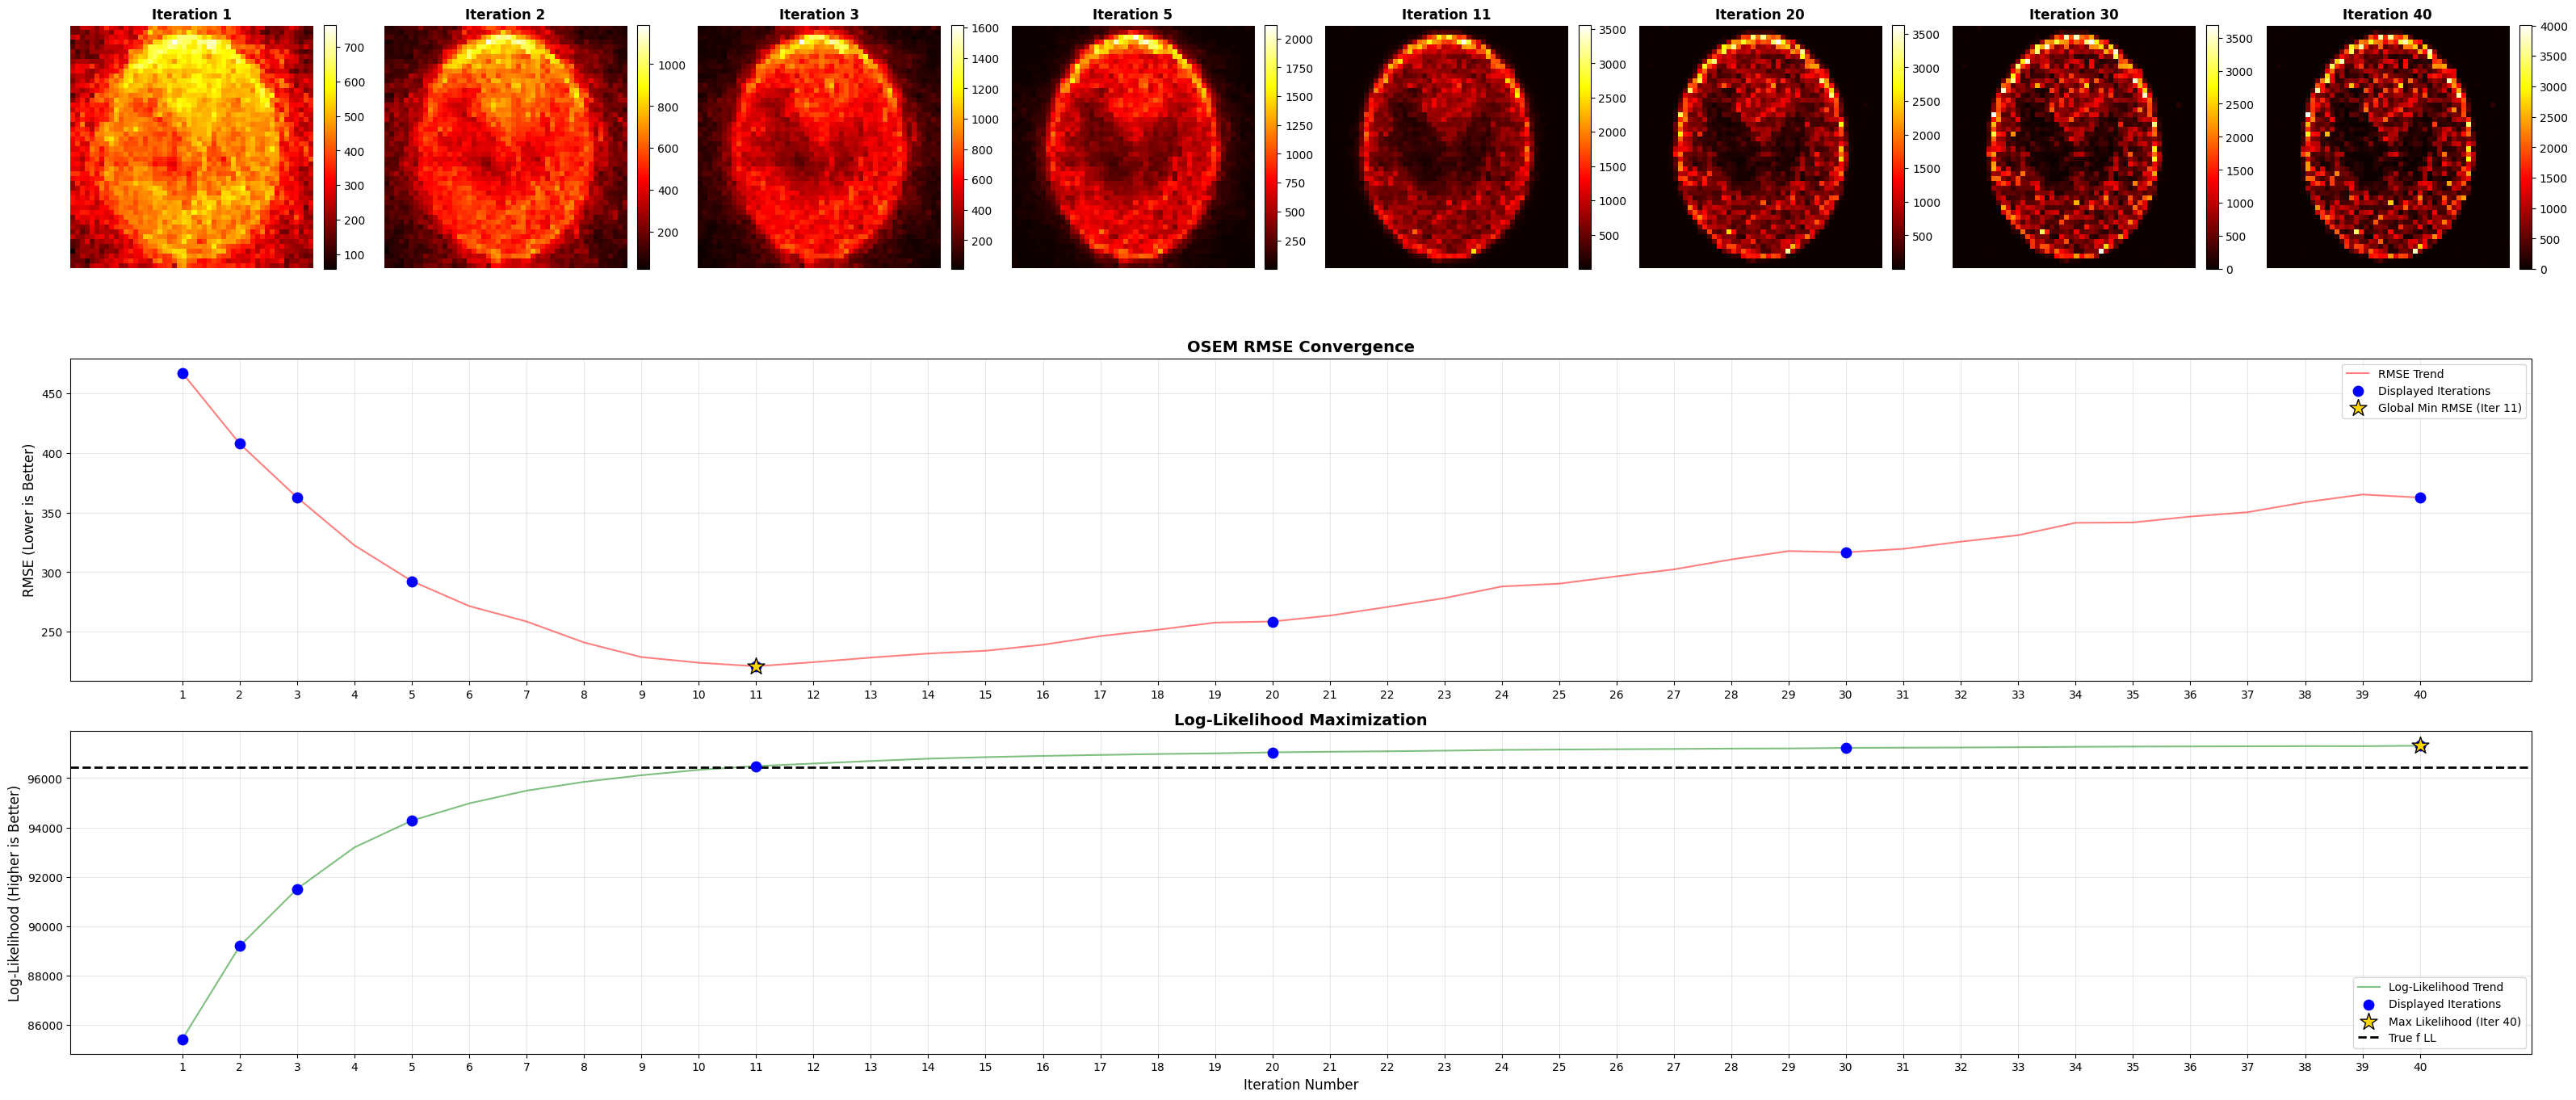

In [ ]:
# --- Simulation Execution and Reconstruction Pipeline ---

# 1. Initialize the PET Simulation Environment
# Configuration based on thesis-level resolution and noise stress-testing
pet = PET(
    B_SQRT=50,       # Image resolution (50x50 pixels)
    D=150,           # Number of detectors
    beta=0.8,        # Attenuation coefficient (High attenuation regime)
    tau=1e-9,        # Coincidence timing window (Controls random noise floor)
    T=1,             # Total scan time (seconds)
    f_factor=1e6     # Activity scaling factor (Total count intensity)
)

# 2. Run the Forward Model
# Generates the ground truth phantom and simulates measured counts (n_star)
# including attenuation, randoms, and Poisson noise.
pet.run_simulation_with_randoms()

# 3. Execute Baseline OSEM Reconstruction
# This will populate self.osem_iters_history and self.osem_mse_hist for convergence analysis.
# Note: n_iters is set high to demonstrate the noise divergence phenomenon.
f_osem_final = pet.reconstruct_osem(n_iters=4, n_subsets=10)

# 4. Visualize the Reconstruction Evolution
# Displays spatial images at specific iterations to highlight the trade-off
# between resolution recovery and noise amplification (early stopping analysis).
pet.plot_osem_evolution(iters_to_show=[1, 2, 3, 5, 11, 20, 30, 40])

True image built. Sum of intensity: 1000000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.


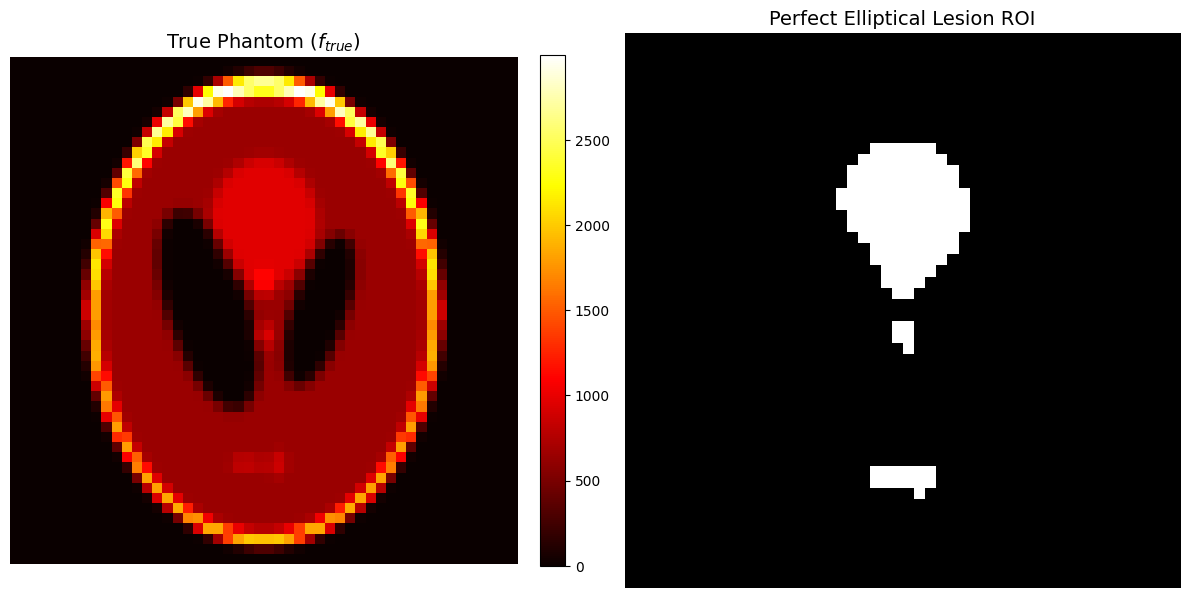

Saved perfect ROI visualization to roi_mask_visualization.png


In [ ]:
pet = PET(
    B_SQRT=50,
    D=150,
    beta=0.8,
    tau=1e-9,
    T=1,
    f_factor=1e6
)

# --- ROI Mask Generation and Visualization ---

def plot_and_save_elliptical_roi(f_true, save_path="roi_mask_visualization.png"):
    """
    Generates a high-fidelity lesion ROI mask by combining spatial elliptical
    constraints with intensity-based thresholding.

    This dual-criteria approach ensures that high-intensity voxels from the
    skull boundary are excluded, focusing the analysis strictly on the
    internal diagnostic lesions.

    Args:
        f_true (numpy.ndarray): The 2D ground truth phantom intensity matrix.
        save_path (str): File path to save the mask visualization. Defaults to "roi_mask_visualization.png".

    Returns:
        numpy.ndarray: A boolean 2D mask where True represents lesion voxels.
    """
    size = f_true.shape[0]

    # 1. Spatial Masking: Define an elliptical region centered in the phantom
    # The radii are tuned to capture the brain interior while avoiding the skull.
    y, x = np.ogrid[:size, :size]
    center_x, center_y = size / 2, size / 2

    radius_x = size * 0.25  # Narrower horizontal radius
    radius_y = size * 0.35  # Longer vertical radius

    # Ellipse equation: (x/a)^2 + (y/b)^2 <= 1
    spatial_mask = (((x - center_x) / radius_x)**2 + ((y - center_y) / radius_y)**2) <= 1

    # 2. Statistical Background Analysis:
    # Calculate the median intensity of brain tissue within the elliptical boundary.
    inner_pixels = f_true[spatial_mask]
    brain_bg = np.median(inner_pixels)

    # 3. Final Lesion Masking:
    # A voxel is considered part of the lesion ROI if it is:
    # a) Inside the spatial ellipse AND
    # b) At least 5% brighter than the brain background.
    lesion_mask = spatial_mask & (f_true > brain_bg * 1.05)

    # --- Visualization for Methodology Section ---
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    # Plot Original Phantom
    im0 = axes[0].imshow(f_true, cmap='hot', interpolation='nearest')
    axes[0].set_title('True Phantom ($f_{true}$)', fontsize=14)
    axes[0].axis('off')
    fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

    # Plot Resulting Binary Mask
    im1 = axes[1].imshow(lesion_mask, cmap='gray', interpolation='nearest')
    axes[1].set_title('Perfect Elliptical Lesion ROI', fontsize=14)
    axes[1].axis('off')

    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

    print(f"Saved perfect ROI visualization to {save_path}")

    return lesion_mask

# --- Execution ---

# Reshape the 1D phantom vector back to 2D for spatial analysis
f_true_2d = pet.f_true.reshape((pet.B_SQRT, pet.B_SQRT))
# Generate and save the lesion mask
exact_lesion_mask = plot_and_save_elliptical_roi(f_true_2d)

True image built. Sum of intensity: 1000000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.
Running Simulation (tau=5e-09)...
Simulation Done. Randoms fraction: 1.26%


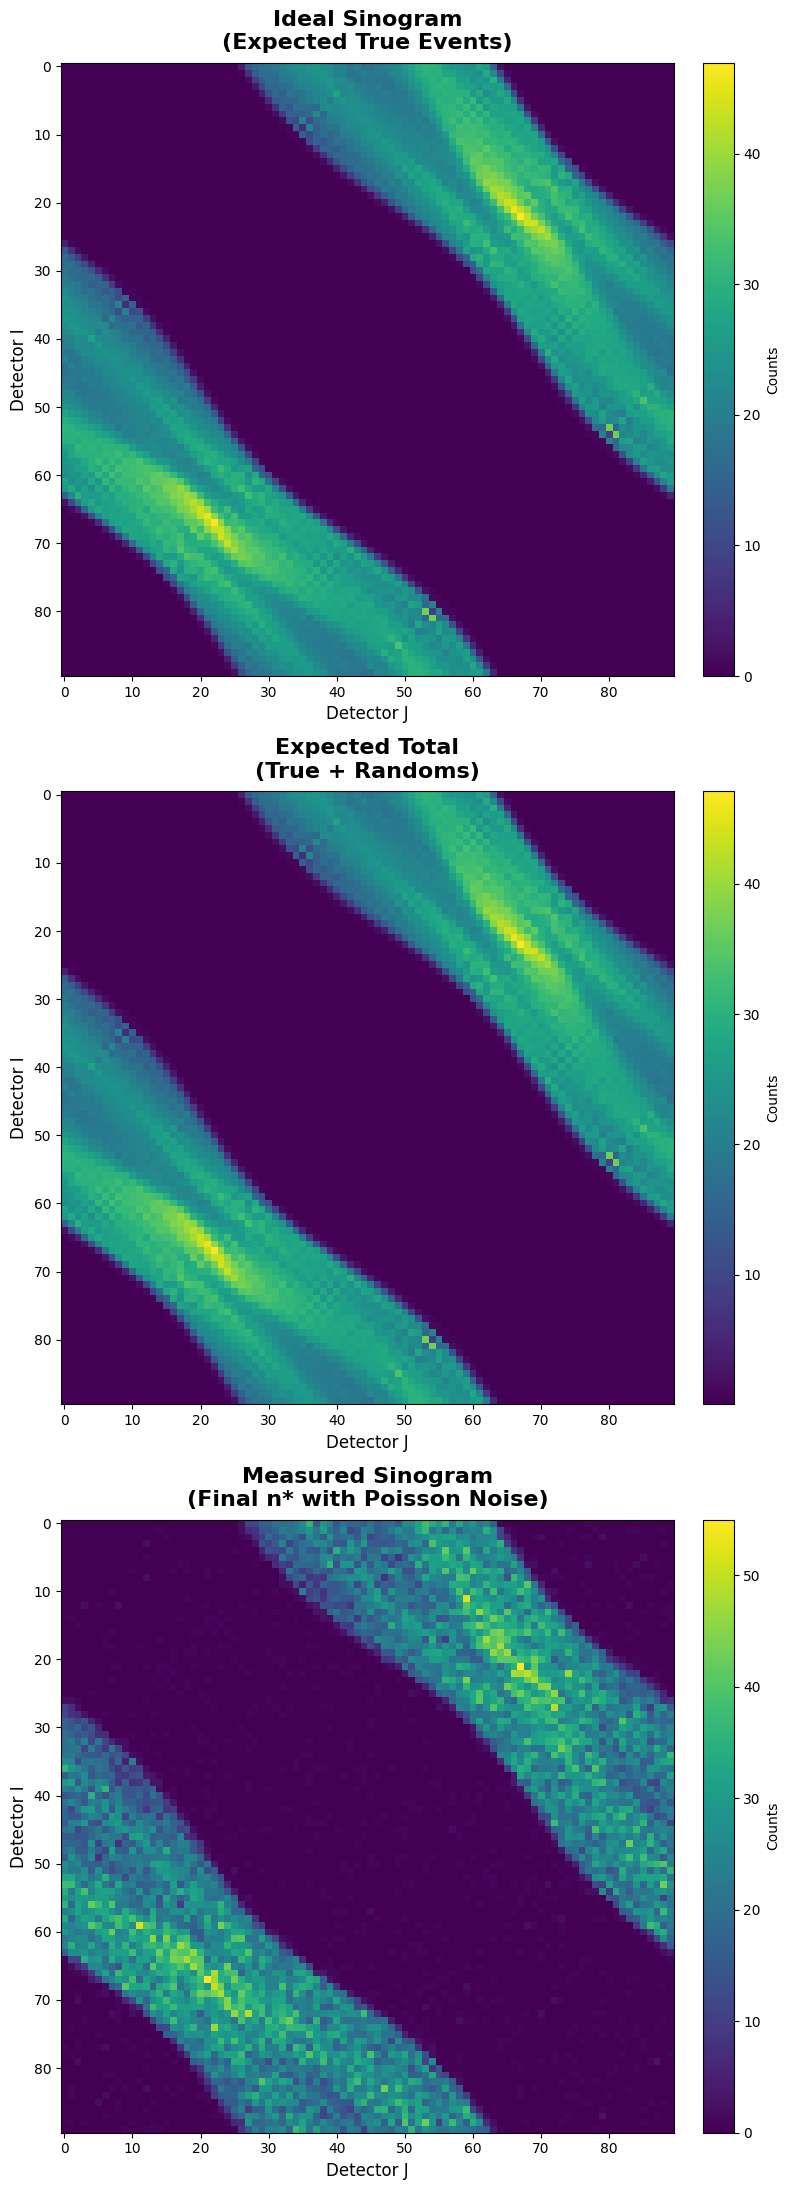

Forward modeling sinograms saved to forward_sinograms_demo.png
[*] Forward modeling complete. Visualization saved as: forward_sinograms_demo.png


In [23]:
# --- 1. Simulation Initialization ---
# We use parameters corresponding to a high-noise scenario (e.g., Scenario 4)
# to clearly visualize the impact of random coincidences and Poisson noise.
pet_example = PET(
    B_SQRT=30,       # Full thesis resolution (50x50 pixels)
    D=90,           # Number of detectors (150-detector ring)
    beta=0.8,        # Attenuation coefficient (High attenuation regime)
    tau=5e-9,        # Coincidence timing window (Realistic high-noise setting)
    T=1,             # Total scan duration (seconds)
    f_factor=1e6     # Activity scaling (Total count intensity)
)

# --- 2. Forward Modeling Execution ---
# This step computes the expected photon counts (lambda) for each LOR
# and generates the noisy measurement vector (n_star) using Poisson sampling.
pet_example.run_simulation_with_randoms()

# --- 3. Visualization for the Methodology Section ---
# This method generates a three-panel comparative figure:
# 1. Ideal Sinogram (Clean signal)
# 2. Expected Total (Signal + Background Randoms)
# 3. Measured Sinogram (Final noisy data with Poisson variance)
pet_example.plot_forward_model_sinograms(save_path="forward_sinograms_demo.png")

print("[*] Forward modeling complete. Visualization saved as: forward_sinograms_demo.png")

# --- 4. Optional Next Steps: Reconstruction ---
# f_osem = pet_example.reconstruct_osem(n_iters=4, n_subsets=10)
# pet_example.plot_osem_evolution(iters_to_show=[1, 2, 3, 4])

Pre-calculating global scale...
True image built. Sum of intensity: 100000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.
Running Simulation (tau=1e-09)...
Simulation Done. Randoms fraction: 0.03%
True image built. Sum of intensity: 500000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.
Running Simulation (tau=1e-09)...
Simulation Done. Randoms fraction: 0.13%
True image built. Sum of intensity: 1000000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.
Running Simulation (tau=1e-09)...
Simulation Done. Randoms fraction: 0.25%


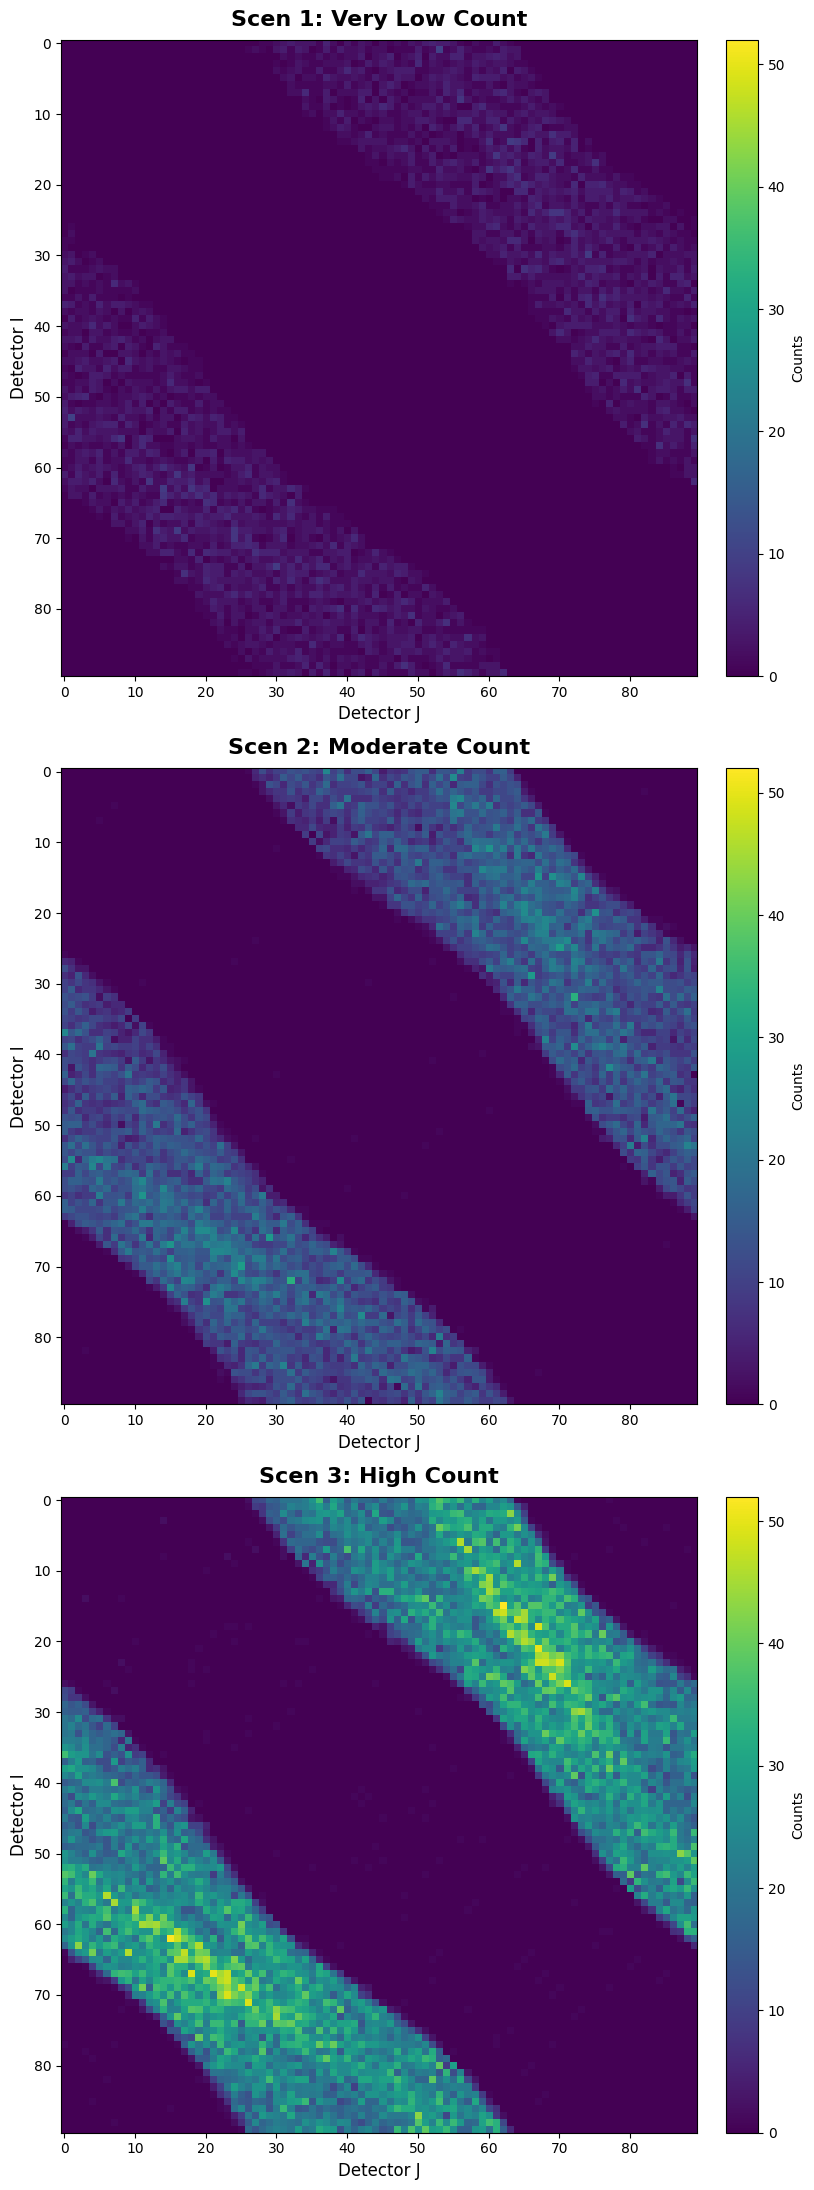

In [21]:
import numpy as np
import matplotlib.pyplot as plt

def plot_sinogram_noise_comparison_v2():
    scenarios = [
        {"f": 1e5, "tau": 1e-9, "title": "Scen 1: Very Low Count"},
        {"f": 5e5, "tau": 1e-9, "title": "Scen 2: Moderate Count"},
        {"f": 1e6, "tau": 1e-9, "title": "Scen 3: High Count"}
    ]

    all_max_values = []
    pet_objects = []

    print("Pre-calculating global scale...")
    for scen in scenarios:
        temp_pet = PET(B_SQRT=30, D=90, beta=0.8, tau=scen["tau"], f_factor=scen["f"], T=1)
        temp_pet.run_simulation_with_randoms()
        all_max_values.append(np.max(temp_pet.n_star))
        pet_objects.append(temp_pet)

    global_vmax = np.max(all_max_values)
    global_vmin = 0

    fig, axes = plt.subplots(3, 1, figsize=(8, 22))
    axes = axes.flatten()

    for i, ax in enumerate(axes):
        im = ax.imshow(pet_objects[i].n_star, cmap='viridis', aspect='equal',
                       vmin=global_vmin, vmax=global_vmax)

        ax.set_title(scenarios[i]["title"], fontsize=16, fontweight='bold', pad=10)
        ax.set_xlabel("Detector J", fontsize=12)
        ax.set_ylabel("Detector I", fontsize=12)

        plt.colorbar(im, ax=ax, label='Counts', fraction=0.046, pad=0.04)

    plt.tight_layout()
    plt.show()

# --- Execution ---
plot_sinogram_noise_comparison_v2()

# **OSEM Grid**

In [18]:
import itertools
import os
import numpy as np
import pandas as pd

# --- 1. Physics Configuration & Scenario Generation ---
physics_config = {
    "B_SQRT": [30],
    "D": [90],
    "f_factor": [1e5, 5e5, 1e6],
    "tau": [1e-9],
    "beta": [0.8],
}


def generate_grid(params_dict):
  """Generates a list of all parameter combinations (Scenarios)."""
  keys, values = zip(*params_dict.items())
  return [dict(zip(keys, combo)) for combo in itertools.product(*values)]


scenarios = generate_grid(physics_config)
output_dir = "thesis_results"
os.makedirs(output_dir, exist_ok=True)

all_results = []
scenario_winners = []

for i, phys in enumerate(scenarios):
  scenario_idx = i + 1
  print(
      f"\n>>> Running Scenario {scenario_idx}/{len(scenarios)}: f_factor="
      f" {phys['f_factor']:.0e}, tau={phys['tau']:.1e}"
  )

  pet = PET(
      B_SQRT=phys["B_SQRT"],
      D=phys["D"],
      beta=phys["beta"],
      tau=phys["tau"],
      f_factor=phys["f_factor"],
  )

  pet.run_simulation_with_randoms()

  best_rmse_in_scenario = float("inf")
  best_scenario_data = {}

  # --- 3. Hyperparameter Optimization (Grid Search for OSEM) ---
  for it in [2, 4]:
    for sub in [4, 6, 8, 10, 12, 16]:
      pet.reconstruct_osem(n_iters=it, n_subsets=sub)

      rmse_hist = np.sqrt(pet.osem_mse_hist)
      min_rmse_run = np.min(rmse_hist)
      best_subiter_idx = int(np.argmin(rmse_hist))

      all_results.append({
          "Scenario": scenario_idx,
          "f_factor": phys["f_factor"],
          "tau": phys["tau"],
          "iters": it,
          "subsets": sub,
          "total_subiters": it * sub,
          "best_subiter": best_subiter_idx + 1,
          "min_RMSE": min_rmse_run,
      })

      if min_rmse_run < best_rmse_in_scenario:
        best_rmse_in_scenario = min_rmse_run
        best_scenario_data = {
            "Scenario": scenario_idx,
            "f_factor": phys["f_factor"],
            "tau": phys["tau"],
            "Optimal_Iters": it,
            "Optimal_Subsets": sub,
            "Total_Subiters": it * sub,
            "Best_Subiter": best_subiter_idx + 1,
            "Best_RMSE": min_rmse_run,
        }

  scenario_winners.append(best_scenario_data)

  print(
      f"Scenario {scenario_idx} Best: Iters="
      f"{best_scenario_data['Optimal_Iters']}, Subsets="
      f"{best_scenario_data['Optimal_Subsets']} --> RMSE:"
      f" {best_rmse_in_scenario:.6f}"
  )

# --- 4. Presentation & Export of Tables ---
results_df = pd.DataFrame(all_results)
results_df.sort_values(
    by=["Scenario", "min_RMSE"], ascending=[True, True], inplace=True
)

print("\n" + "=" * 95)
print("                   ALL OSEM PERMUTATIONS & RMSE (PER SCENARIO)")
print("=" * 95)
print(results_df.to_string(index=False))
results_df.to_csv(f"{output_dir}/osem_all_simulation_results.csv", index=False)

winners_df = pd.DataFrame(scenario_winners)

print("\n" + "=" * 95)
print("                      OSEM WINNERS PER SCENARIO (MIN RMSE)")
print("=" * 95)
print(winners_df.to_string(index=False))
winners_df.to_csv(f"{output_dir}/osem_scenario_winners_summary.csv", index=False)


>>> Running Scenario 1/3: f_factor= 1e+05, tau=1.0e-09
True image built. Sum of intensity: 100000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.
Running Simulation (tau=1e-09)...
Simulation Done. Randoms fraction: 0.03%
Starting OSEM: 2 iterations, 4 subsets...
Iteration 1/2 finished. Current MSE: 5405.2838
Iteration 2/2 finished. Current MSE: 5790.8765
Starting OSEM: 2 iterations, 6 subsets...
Iteration 1/2 finished. Current MSE: 5255.2290
Iteration 2/2 finished. Current MSE: 8885.1005
Starting OSEM: 2 iterations, 8 subsets...
Iteration 1/2 finished. Current MSE: 5933.5879
Iteration 2/2 finished. Current MSE: 12412.5577
Starting OSEM: 2 iterations, 10 subsets...
Iteration 1/2 finished. Current MSE: 7974.1650
Iteration 2/2 finished. Current MSE: 17289.0799
Starting OSEM: 2 iterations, 12 subsets...
Iteration 1/2 finished. Current MSE: 9013.7546
Iteration 2/2 finished.

# **BSREM** **Grid**

In [24]:
import itertools
import os
import numpy as np
import pandas as pd


def generate_grid(params_dict):
    keys, values = zip(*params_dict.items())
    return [dict(zip(keys, combo)) for combo in itertools.product(*values)]

physics_config = {
    "B_SQRT": [30],
    "D": [90],
    "f_factor": [1e5, 5e5, 1e6],
    "tau": [1e-9],
    "beta": [0.8],
}

bsrem_param_grid = {
    "subsets": [10, 20],
    "alphas": [0.05, 0.1, 0.3, 0.5, 1.0],
    "iters": [30, 50],
}

scenarios = generate_grid(physics_config)
output_dir = "thesis_results"
os.makedirs(output_dir, exist_ok=True)

all_bsrem_results = []
scenario_winners = []

for i, phys in enumerate(scenarios):
    scenario_idx = i + 1
    print(f"\n>>> Running Scenario {scenario_idx}/{len(scenarios)}: f_factor={phys['f_factor']:.0e}, tau={phys['tau']:.1e}")

    pet = PET(
        B_SQRT=phys["B_SQRT"],
        D=phys["D"],
        beta=phys["beta"],
        tau=phys["tau"],
        f_factor=phys["f_factor"]
    )
    pet.run_simulation_with_randoms()

    best_scenario_rmse = float('inf')
    best_scenario_run = {}

    for n_sub in bsrem_param_grid["subsets"]:
        for a in bsrem_param_grid["alphas"]:
            for n_it in bsrem_param_grid["iters"]:
                pet.reconstruct_bsrem(n_iters=n_it, n_subsets=n_sub, beta=a, gamma=2.0)

                rmse_history = np.sqrt(pet.bsrem_mse_hist)
                final_rmse = rmse_history[-1]

                run_record = {
                    "Scenario": scenario_idx,
                    "f_factor": phys["f_factor"],
                    "tau": phys["tau"],
                    "alpha": a,
                    "subsets": n_sub,
                    "iters": n_it,
                    "total_subiters": n_it * n_sub,
                    "final_RMSE": final_rmse
                }
                all_bsrem_results.append(run_record)

                if final_rmse < best_scenario_rmse:
                    best_scenario_rmse = final_rmse
                    best_scenario_run = {
                        "Scenario": scenario_idx,
                        "f_factor": phys["f_factor"],
                        "tau": phys["tau"],
                        "Optimal_Alpha": a,
                        "Optimal_Subsets": n_sub,
                        "Optimal_Iters": n_it,
                        "Total_Subiters": n_it * n_sub,
                        "Best_Final_RMSE": final_rmse
                    }

    scenario_winners.append(best_scenario_run)
    print(f"Scenario {scenario_idx} Best: Alpha={best_scenario_run['Optimal_Alpha']}, "
          f"Subsets={best_scenario_run['Optimal_Subsets']}, Iters={best_scenario_run['Optimal_Iters']} "
          f"--> RMSE: {best_scenario_rmse:.6f}")

df_all_permutations = pd.DataFrame(all_bsrem_results)
df_all_permutations.sort_values(by=["Scenario", "final_RMSE"], ascending=[True, True], inplace=True)

df_winners = pd.DataFrame(scenario_winners)

print("\n" + "=" * 95)
print("                   ALL BSREM PERMUTATIONS & RMSE (PER SCENARIO)")
print("=" * 95)
print(df_all_permutations.to_string(index=False))
df_all_permutations.to_csv(f"{output_dir}/bsrem_all_permutations.csv", index=False)

print("\n" + "=" * 95)
print("                      BSREM WINNERS PER SCENARIO (MIN RMSE)")
print("=" * 95)
print(df_winners.to_string(index=False))
df_winners.to_csv(f"{output_dir}/bsrem_scenario_winners.csv", index=False)


>>> Running Scenario 1/3: f_factor=1e+05, tau=1.0e-09
True image built. Sum of intensity: 100000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.
Running Simulation (tau=1e-09)...
Simulation Done. Randoms fraction: 0.03%
Starting Auto-Scaled BSREM: Beta=0.05, Gamma=2.0, 30 iters...
  -> Effective Beta (scaled): 4.00e-04
BSREM Iter 1/30 | MSE: 6287.8127
BSREM Iter 6/30 | MSE: 15589.1514
BSREM Iter 11/30 | MSE: 16555.3161


KeyboardInterrupt: 

# **Simulation Study**

In [4]:
import os
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==============================================================================
# 1. FIXED PARAMETERS FROM OPTIMIZATION PHASE
# ==============================================================================

N_MC = 1

osem_optimal_configs = {
    1e5: (4, 4),
    5e5: (4, 4),
    1e6: (4, 4)
}

bsrem_optimal_configs = {
    1e5: (0.3, 10, 50),
    5e5: (0.1, 10, 50),
    1e6: (0.1, 10, 30)
}

clinical_configs = {
    "iters": 2,
    "subsets": 20
}

clinical_bsrem_config = {
    "beta": 0.2,
    "iters": 40,
    "subsets": 10
}

experiment_config = {
    "physics": {
        "B_SQRT": [30],
        "D": [90],
        "f_factor": [1e5, 5e5, 1e6],
        "tau": [1e-9],
        "beta_physics": [0.8]
    },
    "oracle": {
        "G": 100,
        "burn_in": 20,
        "n_prior_points": 1000,
        "window_size": 101
    }
}

# ==============================================================================
# 2. MASTER PLOTTING FUNCTION
# ==============================================================================

def plot_master_comparison(pet, results_dict, rows_to_plot, save_prefix):
    """
    Plots the master comparison suite including True Phantom, Optimal OSEM,
    Optimal BSREM, Clinical BSREM, Shepp-Vardi EM, Clinical OSEM, and the SINGLE Oracle from EM.
    """
    B = pet.B_SQRT
    f_true_2d = pet.f_true.reshape(B, B) if pet.f_true.ndim == 1 else pet.f_true
    f_true_flat = f_true_2d.flatten()

    names = ["True Phantom"] + list(results_dict.keys())

    imgs_2d = [f_true_2d]
    for d in results_dict.values():
        img = d['img']
        imgs_2d.append(img.reshape(B, B) if img.ndim == 1 else img)

    # 7 colors needed: True + Opt OSEM + Opt BSREM + Clin BSREM + EM + Clin OSEM + Oracle
    colors = ['black', 'blue', 'purple', 'orange', 'cyan', 'green', 'magenta']

    # --- 1. Images Grid ---
    num_images = len(names)
    fig, axes = plt.subplots(1, num_images, figsize=(4.5 * num_images, 5))
    fig.suptitle("Visual Comparison (MC Trial 1): Baselines & Oracle", fontsize=22, fontweight='bold', y=1.05)
    global_max = np.max(f_true_2d) * 1.2

    for i, (name, img_2d) in enumerate(zip(names, imgs_2d)):
        ax = axes[i]
        im = ax.imshow(img_2d, cmap='hot', aspect='auto', vmin=0, vmax=global_max)
        if name == "True Phantom":
            ax.set_title(name, fontsize=16, fontweight='bold')
        else:
            rmse, snr = results_dict[name].get('rmse', 0), results_dict[name].get('snr', 0)
            ax.set_title(f"{name.replace('_', ' ')}\nRMSE: {rmse:.2f} | SNR: {snr:.2f}dB", fontsize=13, fontweight='bold')
        ax.axis('off')
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    plt.tight_layout()
    plt.savefig(f"{save_prefix}_01_Images.png", dpi=200, bbox_inches='tight')
    plt.close()

    # --- 2. Line Profiles ---
    for row in rows_to_plot:
        if row >= B: continue

        plt.figure(figsize=(16, 8))
        plt.title(f"Line Profile Comparison - Row {row}", fontsize=18, fontweight='bold')
        plt.plot(f_true_2d[row, :], label="True Phantom", color='black', linewidth=4, linestyle='--')

        for i, (name, img_2d) in enumerate(zip(names[1:], imgs_2d[1:])):
            plt.plot(img_2d[row, :], label=name.replace('_', ' '), color=colors[i+1], linewidth=2, alpha=0.8)

        plt.xlabel("Pixel Index", fontsize=14)
        plt.ylabel("Intensity", fontsize=14)
        plt.grid(True, alpha=0.3)
        plt.legend(fontsize=10, loc='upper right', bbox_to_anchor=(1.25, 1))
        plt.tight_layout()
        plt.savefig(f"{save_prefix}_02_LineProfile_Row_{row}.png", dpi=200, bbox_inches='tight')
        plt.close()

    # --- 3. Statistical Shrinkage Analysis ---
    # Only map the Shepp-Vardi EM Oracle
    oracle_mapping = {
        "Shepp-Vardi_EM": "Oracle_Gibbs_Shepp-Vardi_EM"
    }

    for init_name, oracle_name in oracle_mapping.items():
        if init_name in results_dict and oracle_name in results_dict:
            init_flat = results_dict[init_name]['img'].flatten()
            oracle_flat = results_dict[oracle_name]['img'].flatten()

            plt.figure(figsize=(10, 8))
            plt.title(f"Statistical Shrinkage: {oracle_name.replace('_', ' ')} vs {init_name.replace('_', ' ')}", fontsize=16, fontweight='bold')

            plt.scatter(init_flat, f_true_flat, color='orange', s=10, label="Ground Truth Ref")
            plt.scatter(init_flat, oracle_flat, color='blue', s=20, alpha=0.3, label=f"Oracle vs Init")

            max_val = max(np.max(init_flat), np.max(oracle_flat), np.max(f_true_flat))
            plt.plot([0, max_val], [0, max_val], color='black', linestyle='--', alpha=0.6, label="Identity Line")

            plt.xlabel(f"{init_name.replace('_', ' ')} Intensity (Initial Estimate)", fontsize=14)
            plt.ylabel("Intensity (Oracle / Ground Truth)", fontsize=14)
            plt.grid(True, alpha=0.3)
            plt.legend(fontsize=12, loc='upper left')
            plt.tight_layout()
            plt.savefig(f"{save_prefix}_03_Shrinkage_{init_name}.png", dpi=200, bbox_inches='tight')
            plt.close()

    # --- 4. Convergence Graphs ---
    metrics_to_plot = [
        ('history_mse', 'Mean Squared Error (MSE)', 'MSE Convergence', True),
        ('history_snr', 'Signal-to-Noise Ratio (dB)', 'SNR Convergence', False),
        ('history_ll', 'Log-Likelihood Maximization', 'Log-Likelihood Maximization', False)
    ]

    true_ll = None
    if hasattr(pet, 'calculate_ll'):
        try:
            true_ll = pet.calculate_ll(pet.f_true)
        except:
            pass

    for key, ylabel, title, is_log_scale in metrics_to_plot:
        plt.figure(figsize=(16, 8))
        plt.title(title, fontsize=18, fontweight='bold')

        has_data = False
        max_x_axis = 10

        for d in results_dict.values():
            if d.get(key) is not None and len(d[key]) > 0:
                max_x_axis = max(max_x_axis, len(d[key]))

        if "Log-Likelihood" in title and true_ll is not None:
            plt.axhline(y=true_ll, color='black', linestyle='-', linewidth=3, label="True Phantom LL")
            has_data = True

        for i, (name, data) in enumerate(results_dict.items()):
            hist = data.get(key)
            if hist is not None and len(hist) > 0:
                has_data = True
                iters = range(1, len(hist) + 1)
                plt.plot(iters, hist, label=name.replace('_', ' '), color=colors[i+1], linewidth=2, marker='o', markersize=4)

            elif "Log-Likelihood" in title and data.get('final_ll') is not None and not np.isnan(data['final_ll']):
                has_data = True
                plt.plot([1, max_x_axis], [data['final_ll'], data['final_ll']], label=f"{name.replace('_', ' ')} (Final LL)", color=colors[i+1], linewidth=2, linestyle='-.')

        if has_data:
            plt.xlabel("Iteration / Gibbs Sample", fontsize=14)
            plt.ylabel(ylabel, fontsize=14)
            if is_log_scale:
                plt.yscale('log')
            plt.grid(True, which="both", alpha=0.3)
            plt.legend(fontsize=10, loc='lower right' if 'Log' in title else 'upper right', bbox_to_anchor=(1.25, 1))
            plt.tight_layout()
            plt.savefig(f"{save_prefix}_04_Conv_{title.split()[0]}.png", dpi=200, bbox_inches='tight')
        plt.close()

    # --- 5. Intensity Histograms ---
    num_methods = len(names) - 1
    fig, axes = plt.subplots(1, num_methods, figsize=(5 * num_methods, 5))
    fig.suptitle("Intensity Distribution: Methods vs True Phantom", fontsize=24, fontweight='bold', y=1.05)

    if num_methods == 1:
        axes = [axes]

    for i, (name, img_2d) in enumerate(zip(names[1:], imgs_2d[1:])):
        ax = axes[i]
        ax.hist(f_true_flat, bins=100, alpha=0.3, color='black', label='True Phantom', density=True)
        ax.hist(img_2d.flatten(), bins=100, histtype='step', color=colors[i+1], label=name.replace('_', ' '), linewidth=2, density=True)

        ax.set_title(name.replace('_', '\n'), fontsize=14, fontweight='bold')
        ax.set_xlabel("Pixel Intensity", fontsize=12)
        if i == 0:
            ax.set_ylabel("Density", fontsize=12)
        ax.set_yscale('log')
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=10, loc='upper right')

    plt.tight_layout()
    plt.savefig(f"{save_prefix}_05_Histograms.png", dpi=200, bbox_inches='tight')
    plt.close()

# ==============================================================================
# 3. FINAL PRODUCTION EXECUTION ENGINE (MONTE CARLO LOOP)
# ==============================================================================

output_dir = "final_thesis_production_MC"
os.makedirs(output_dir, exist_ok=True)

def generate_grid(params_dict):
    keys, values = zip(*params_dict.items())
    return [dict(zip(keys, combo)) for combo in itertools.product(*values)]

scenarios = generate_grid(experiment_config["physics"])
mc_master_table = []

print(f"--- Starting Monte Carlo Production Run: {len(scenarios)} Scenarios, {N_MC} Trials each ---")

for i, phys in enumerate(scenarios):
    f_val = phys['f_factor']
    print("\n" + "█"*80)
    print(f" SCENARIO {i+1}/{len(scenarios)} | f={f_val:.0e} | tau={phys['tau']:.1e} | N_MC={N_MC}")
    print("█"*80)

    for mc in range(N_MC):
        print(f"\n--- MC Trial {mc+1}/{N_MC} ---")

        current_seed = 42 + mc + (i * 100)

        pet = PET(
            B_SQRT=phys["B_SQRT"], D=phys["D"],
            beta=phys["beta_physics"], tau=phys["tau"], f_factor=f_val, T=1,
            seed=current_seed
        )
        pet.run_simulation_with_randoms()

        scenario_results = {}
        trial_metrics = {"Scenario": i+1, "f_factor": f_val, "MC_Trial": mc+1}

        def execute_and_store(name, func, kwargs, hist_prefix):
            print(f"Running: {name}...")
            img = func(**kwargs)

            _, rmse, snr = pet._get_metrics(img)

            final_ll = np.nan
            if hasattr(pet, 'calculate_ll'):
                try:
                    final_ll = pet.calculate_ll(img)
                except Exception:
                    pass

            def get_robust_hist(keywords):
                for kw in keywords:
                    exact_names = [f"{hist_prefix}_{kw}", f"{kw}"]
                    for exact in exact_names:
                        if hasattr(pet, exact):
                            val = getattr(pet, exact)
                            if isinstance(val, (list, np.ndarray)) and len(val) > 0:
                                return list(val)

                for k, v in pet.__dict__.items():
                    if hist_prefix in k.lower() and any(kw in k.lower() for kw in keywords):
                        if isinstance(v, (list, np.ndarray)) and len(v) > 0:
                            return list(v)
                return []

            hist_mse = get_robust_hist(["mse_hist", "rmse_hist", "mse", "rmse"])
            hist_snr = get_robust_hist(["snr_hist", "snr"])
            hist_ll  = get_robust_hist(["ll_hist", "loglik_hist", "log_likelihood", "ll", "objs"])

            scenario_results[name] = {
                'img': img,
                'rmse': rmse,
                'snr': snr,
                'final_ll': final_ll,
                'history_mse': hist_mse,
                'history_snr': hist_snr,
                'history_ll': hist_ll
            }
            trial_metrics[f"RMSE_{name}"] = rmse
            trial_metrics[f"SNR_{name}"] = snr
            return img

        # 1. Optimal OSEM Baseline
        o_it, o_sub = osem_optimal_configs[f_val]
        f_opt_osem = execute_and_store("Optimal_OSEM", pet.reconstruct_osem, {"n_iters": o_it, "n_subsets": o_sub}, "osem")

        # 2. Optimal BSREM Baseline
        b_val, s_val, i_val = bsrem_optimal_configs[f_val]
        f_opt_bsrem = execute_and_store("Optimal_BSREM", pet.reconstruct_bsrem, {"n_iters": i_val, "n_subsets": s_val, "beta": b_val, "gamma": 2.0}, "bsrem")

        # 3. Clinical BSREM Baseline
        f_clin_bsrem = execute_and_store("Clinical_BSREM", pet.reconstruct_bsrem, {"n_iters": clinical_bsrem_config["iters"], "n_subsets": clinical_bsrem_config["subsets"], "beta": clinical_bsrem_config["beta"], "gamma": 2.0}, "bsrem")

        # 4. Shepp-Vardi EM Baseline (Global MLE)
        def run_yigal_wrapper(num_iter, solver_eps, use_beta):
            llik_lst, mse_lst, f_lst = pet.reconstruct_yigal_em(num_iter=num_iter, solver_eps=solver_eps, use_beta=use_beta)
            pet.yigal_ll_hist = llik_lst
            pet.yigal_mse_hist = mse_lst
            return f_lst[-1]

        f_shepp_vardi = execute_and_store("Shepp-Vardi_EM", run_yigal_wrapper, {"num_iter": 50, "solver_eps": 1e-5, "use_beta": 0.0}, "yigal")

        # 5. Clinical OSEM Baseline (2x20)
        f_clin_osem = execute_and_store("Clinical_OSEM_2x20", pet.reconstruct_osem, {"n_iters": clinical_configs["iters"], "n_subsets": clinical_configs["subsets"]}, "osem")

        # 6. Oracle Gibbs Init: ONLY from Shepp-Vardi EM
        ora_c = experiment_config["oracle"]
        _ = execute_and_store("Oracle_Gibbs_Shepp-Vardi_EM", pet.run_oracle_gibbs,
            {"G": ora_c["G"], "burn_in": ora_c["burn_in"], "f_start": f_shepp_vardi,
             "n_prior_points": ora_c["n_prior_points"], "window_size": ora_c["window_size"]}, "oracle")

        mc_master_table.append(trial_metrics)

        # Plot ONLY for the first MC trial of each scenario
        if mc == 0:
            prefix = f"{output_dir}/Final_Scen_{i+1}_MC_Trial_1"
            print("Generating Master Comparison Plots for Trial 1...")
            rows_to_plot = [phys["B_SQRT"] // 2, int(phys["B_SQRT"] * 0.65)]
            plot_master_comparison(pet, scenario_results, rows_to_plot, save_prefix=prefix)

# ==============================================================================
# 4. MONTE CARLO SUMMARY EXPORT
# ==============================================================================
df_mc = pd.DataFrame(mc_master_table)
df_mc.to_csv(f"{output_dir}/Full_MC_Results.csv", index=False)

cols_to_agg = [c for c in df_mc.columns if c.startswith('RMSE_') or c.startswith('SNR_')]
summary_df = df_mc.groupby(['Scenario', 'f_factor'])[cols_to_agg].agg(['mean', 'sem']).round(2)
summary_df.to_csv(f"{output_dir}/MC_Summary_Statistics.csv")

print("\n" + "="*90)
print(f"FINAL MONTE CARLO SUMMARY (N={N_MC}) - MEAN ± SE")
print("="*90)

# Print a cleaner formatted summary to console
for (scen, f_val), row in summary_df.iterrows():
    print(f"\n--- SCENARIO {scen} (f={f_val:.0e}) ---")

    methods_to_print = [
        "Optimal_OSEM", "Optimal_BSREM", "Clinical_BSREM", "Shepp-Vardi_EM",
        "Clinical_OSEM_2x20", "Oracle_Gibbs_Shepp-Vardi_EM"
    ]

    for method in methods_to_print:
        rmse_m, rmse_se = row[(f'RMSE_{method}', 'mean')], row[(f'RMSE_{method}', 'sem')]
        snr_m, snr_se = row[(f'SNR_{method}', 'mean')], row[(f'SNR_{method}', 'sem')]
        print(f"{method:30s} | RMSE: {rmse_m:8.2f} ± {rmse_se:6.2f} | SNR: {snr_m:5.2f} ± {snr_se:4.2f} dB")

--- Starting Monte Carlo Production Run: 3 Scenarios, 1 Trials each ---

████████████████████████████████████████████████████████████████████████████████
 SCENARIO 1/3 | f=1e+05 | tau=1.0e-09 | N_MC=1
████████████████████████████████████████████████████████████████████████████████

--- MC Trial 1/1 ---
True image built. Sum of intensity: 100000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.
Running Simulation (tau=1e-09)...
Simulation Done. Randoms fraction: 0.03%
Running: Optimal_OSEM...
Starting OSEM: 4 iterations, 4 subsets...
Iteration 1/4 finished. Current MSE: 5284.9331
Iteration 2/4 finished. Current MSE: 5941.4124
Iteration 3/4 finished. Current MSE: 9267.1236
Iteration 4/4 finished. Current MSE: 12927.5663
Running: Optimal_BSREM...
Starting Auto-Scaled BSREM: Beta=0.3, Gamma=2.0, 50 iters...
  -> Effective Beta (scaled): 2.40e-03
BSREM Iter 1/50 | MSE: 4214.44

Generating Master Comparison Plots for Trial 1...

████████████████████████████████████████████████████████████████████████████████
 SCENARIO 2/3 | f=5e+05 | tau=1.0e-09 | N_MC=1
████████████████████████████████████████████████████████████████████████████████

--- MC Trial 1/1 ---
True image built. Sum of intensity: 500000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.
Running Simulation (tau=1e-09)...
Simulation Done. Randoms fraction: 0.13%
Running: Optimal_OSEM...
Starting OSEM: 4 iterations, 4 subsets...
Iteration 1/4 finished. Current MSE: 111330.2377
Iteration 2/4 finished. Current MSE: 66878.5388
Iteration 3/4 finished. Current MSE: 71579.3625
Iteration 4/4 finished. Current MSE: 88248.8469
Running: Optimal_BSREM...
Starting Auto-Scaled BSREM: Beta=0.1, Gamma=2.0, 50 iters...
  -> Effective Beta (scaled): 8.00e-04
BSREM Iter 1/50 | MSE: 61842.3494
BSREM Iter 6/5

Generating Master Comparison Plots for Trial 1...

████████████████████████████████████████████████████████████████████████████████
 SCENARIO 3/3 | f=1e+06 | tau=1.0e-09 | N_MC=1
████████████████████████████████████████████████████████████████████████████████

--- MC Trial 1/1 ---
True image built. Sum of intensity: 1000000.00
Initializing P_xmat...
Building Gibbs structures...
Gibbs structures ready.
Cleaning up memory...
PET Object initialized. Ready for simulation and reconstruction.
Running Simulation (tau=1e-09)...
Simulation Done. Randoms fraction: 0.25%
Running: Optimal_OSEM...
Starting OSEM: 4 iterations, 4 subsets...
Iteration 1/4 finished. Current MSE: 453025.7596
Iteration 2/4 finished. Current MSE: 225310.8282
Iteration 3/4 finished. Current MSE: 182050.3021
Iteration 4/4 finished. Current MSE: 191054.4358
Running: Optimal_BSREM...
Starting Auto-Scaled BSREM: Beta=0.1, Gamma=2.0, 30 iters...
  -> Effective Beta (scaled): 8.00e-04
BSREM Iter 1/30 | MSE: 218782.2640
BSREM Ite

Generating Master Comparison Plots for Trial 1...

FINAL MONTE CARLO SUMMARY (N=1) - MEAN ± SE

--- SCENARIO 1 (f=1e+05) ---
Optimal_OSEM                   | RMSE:   113.70 ±    nan | SNR:  3.52 ±  nan dB
Optimal_BSREM                  | RMSE:    65.27 ±    nan | SNR:  8.34 ±  nan dB
Clinical_BSREM                 | RMSE:    73.12 ±    nan | SNR:  7.35 ±  nan dB
Shepp-Vardi_EM                 | RMSE:   160.27 ±    nan | SNR:  0.54 ±  nan dB
Clinical_OSEM_2x20             | RMSE:   180.58 ±    nan | SNR: -0.50 ±  nan dB
Oracle_Gibbs_Shepp-Vardi_EM    | RMSE:    77.70 ±    nan | SNR:  6.83 ±  nan dB

--- SCENARIO 2 (f=5e+05) ---
Optimal_OSEM                   | RMSE:   297.07 ±    nan | SNR:  9.16 ±  nan dB
Optimal_BSREM                  | RMSE:   236.21 ±    nan | SNR: 11.15 ±  nan dB
Clinical_BSREM                 | RMSE:   251.08 ±    nan | SNR: 10.62 ±  nan dB
Shepp-Vardi_EM                 | RMSE:   446.64 ±    nan | SNR:  5.61 ±  nan dB
Clinical_OSEM_2x20             | RMSE:   431.